In [1]:
from juliacall import Main as jl, convert as jlconvert
import juliacall

path_to_julia_tn = "../../z2chain/Z2HiggsChainDynamics.jl"
path_to_julia_mpf = "../../utils/MultiProductF.jl"
jl.seval(f"include(\"{path_to_julia_tn}\")")
jl.seval(f"include(\"{path_to_julia_mpf}\")")
jl.seval("using .Z2HiggsChainDynamics")
jl.seval("using .MultiProductF")

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


# Longer times

## Simulation settings

In [2]:
L = 15
m = 5
g = 0.8
lamb = 1

final_time = 10

particle_pair_left_position = 4
particle_pair_length = 6

x_basis = False

## Error bounds

In [3]:
from z2chain.circs import trotter_dt
import numpy as np

desired_error = 3.2e-4

error_dt = trotter_dt(desired_error, L, m, g, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"To guarantee the desired error, Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*4} 2Qb depth)")

To guarantee the desired error, Δt should be:
Δt = 0.00956
To correctly reach the desired final time, the number of layers required is:
N = 1046 (4184 2Qb depth)


## (Almost) ground truth

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import os

dt = 0.01
steps = int(np.ceil(final_time/dt))
cutoff = 1e-12

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_xbasis_{x_basis}_steps_{steps}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt, steps, x_basis, False, cutoff, filepath)
    observable_matrix = np.array(observable_matrix)
    save_site_gauge_observable_matrix(observable_matrix, filepath)
else:
    observable_matrix = load_site_gauge_observable_matrix(filepath)

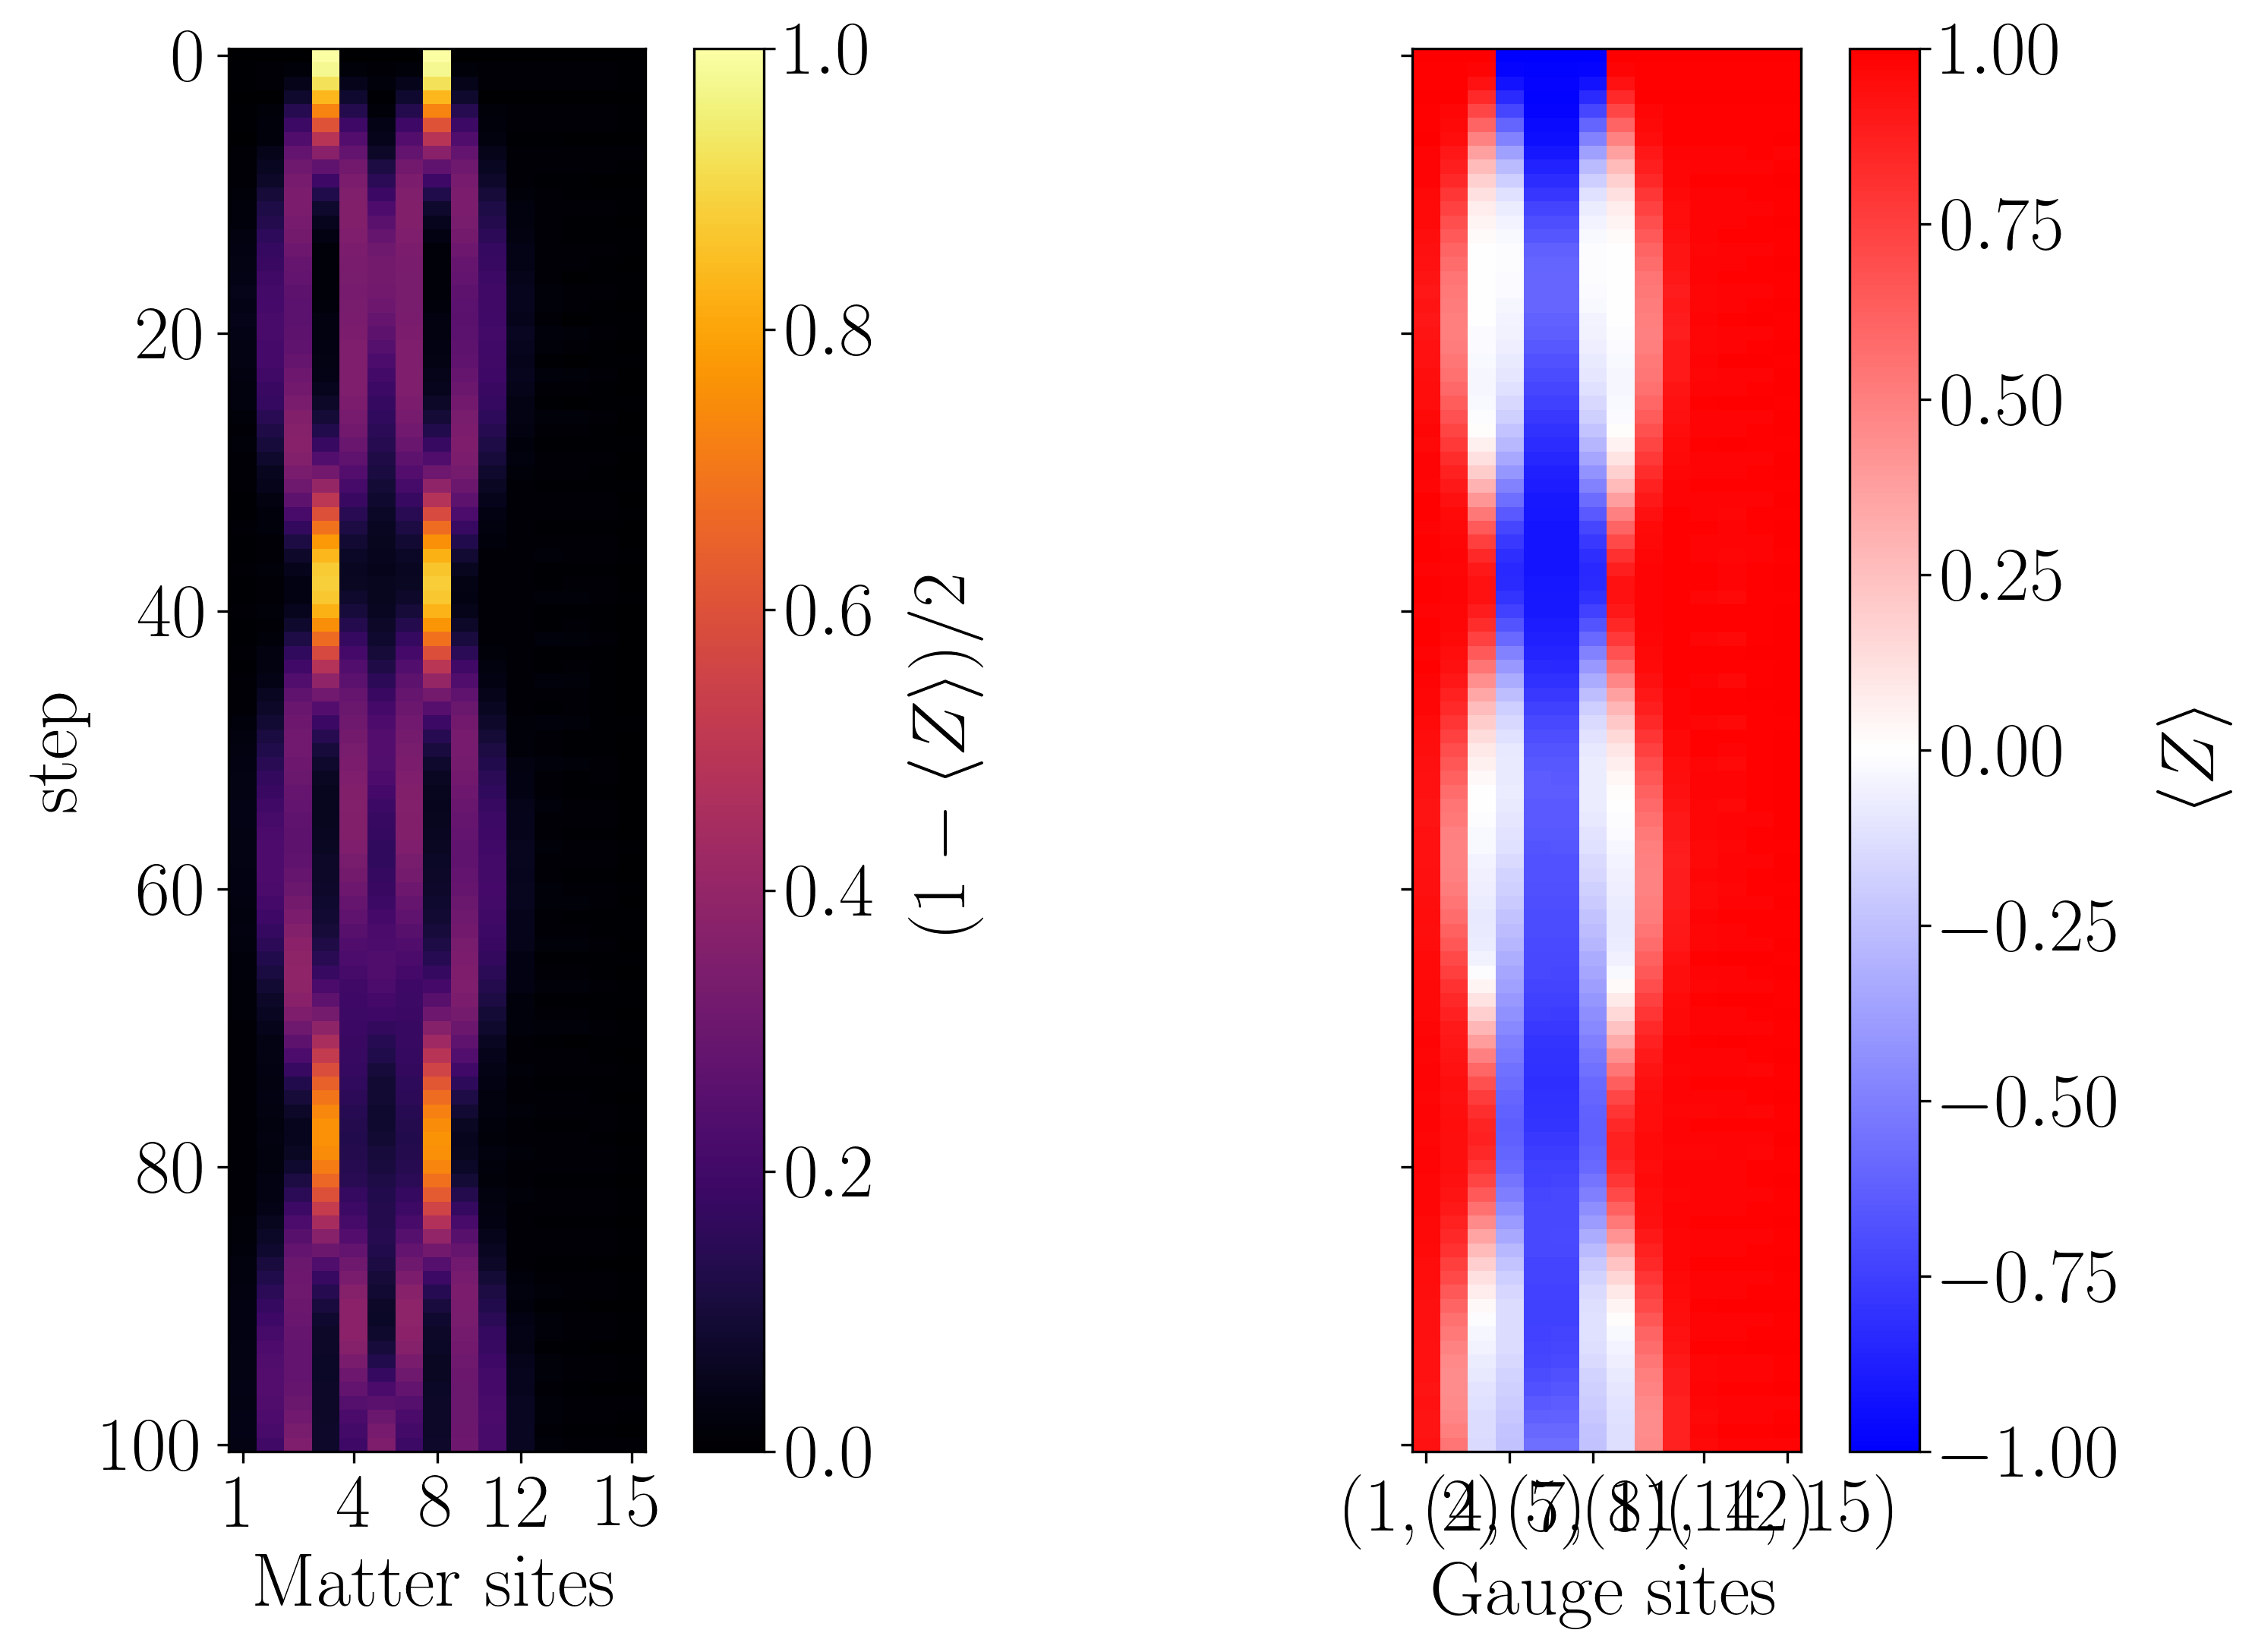

In [5]:
from z2chain.plotting import x_t_separated_plot

ploteach = 10

x_t_separated_plot(observable_matrix[::ploteach, :])

## Multiproduct formulas

In [4]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp = 0.29411765
steps_mp = int(np.ceil(final_time/dt_mp))
# comparison_increment_mp = int(dt_mp/dt)
multiproduct_lambda = 2
cutoff = 1e-12

filepath = f"Results/tnjulia_multiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_mplamb_{multiproduct_lambda}_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix = jl.Z2HiggsChainDynamics.multiproduct_simulation_2order_first_try(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, multiproduct_lambda, cutoff)
    observable_matrix = np.array(observable_matrix)
    save_site_gauge_observable_matrix(observable_matrix, filepath)
else:
    observable_matrix = load_site_gauge_observable_matrix(filepath)

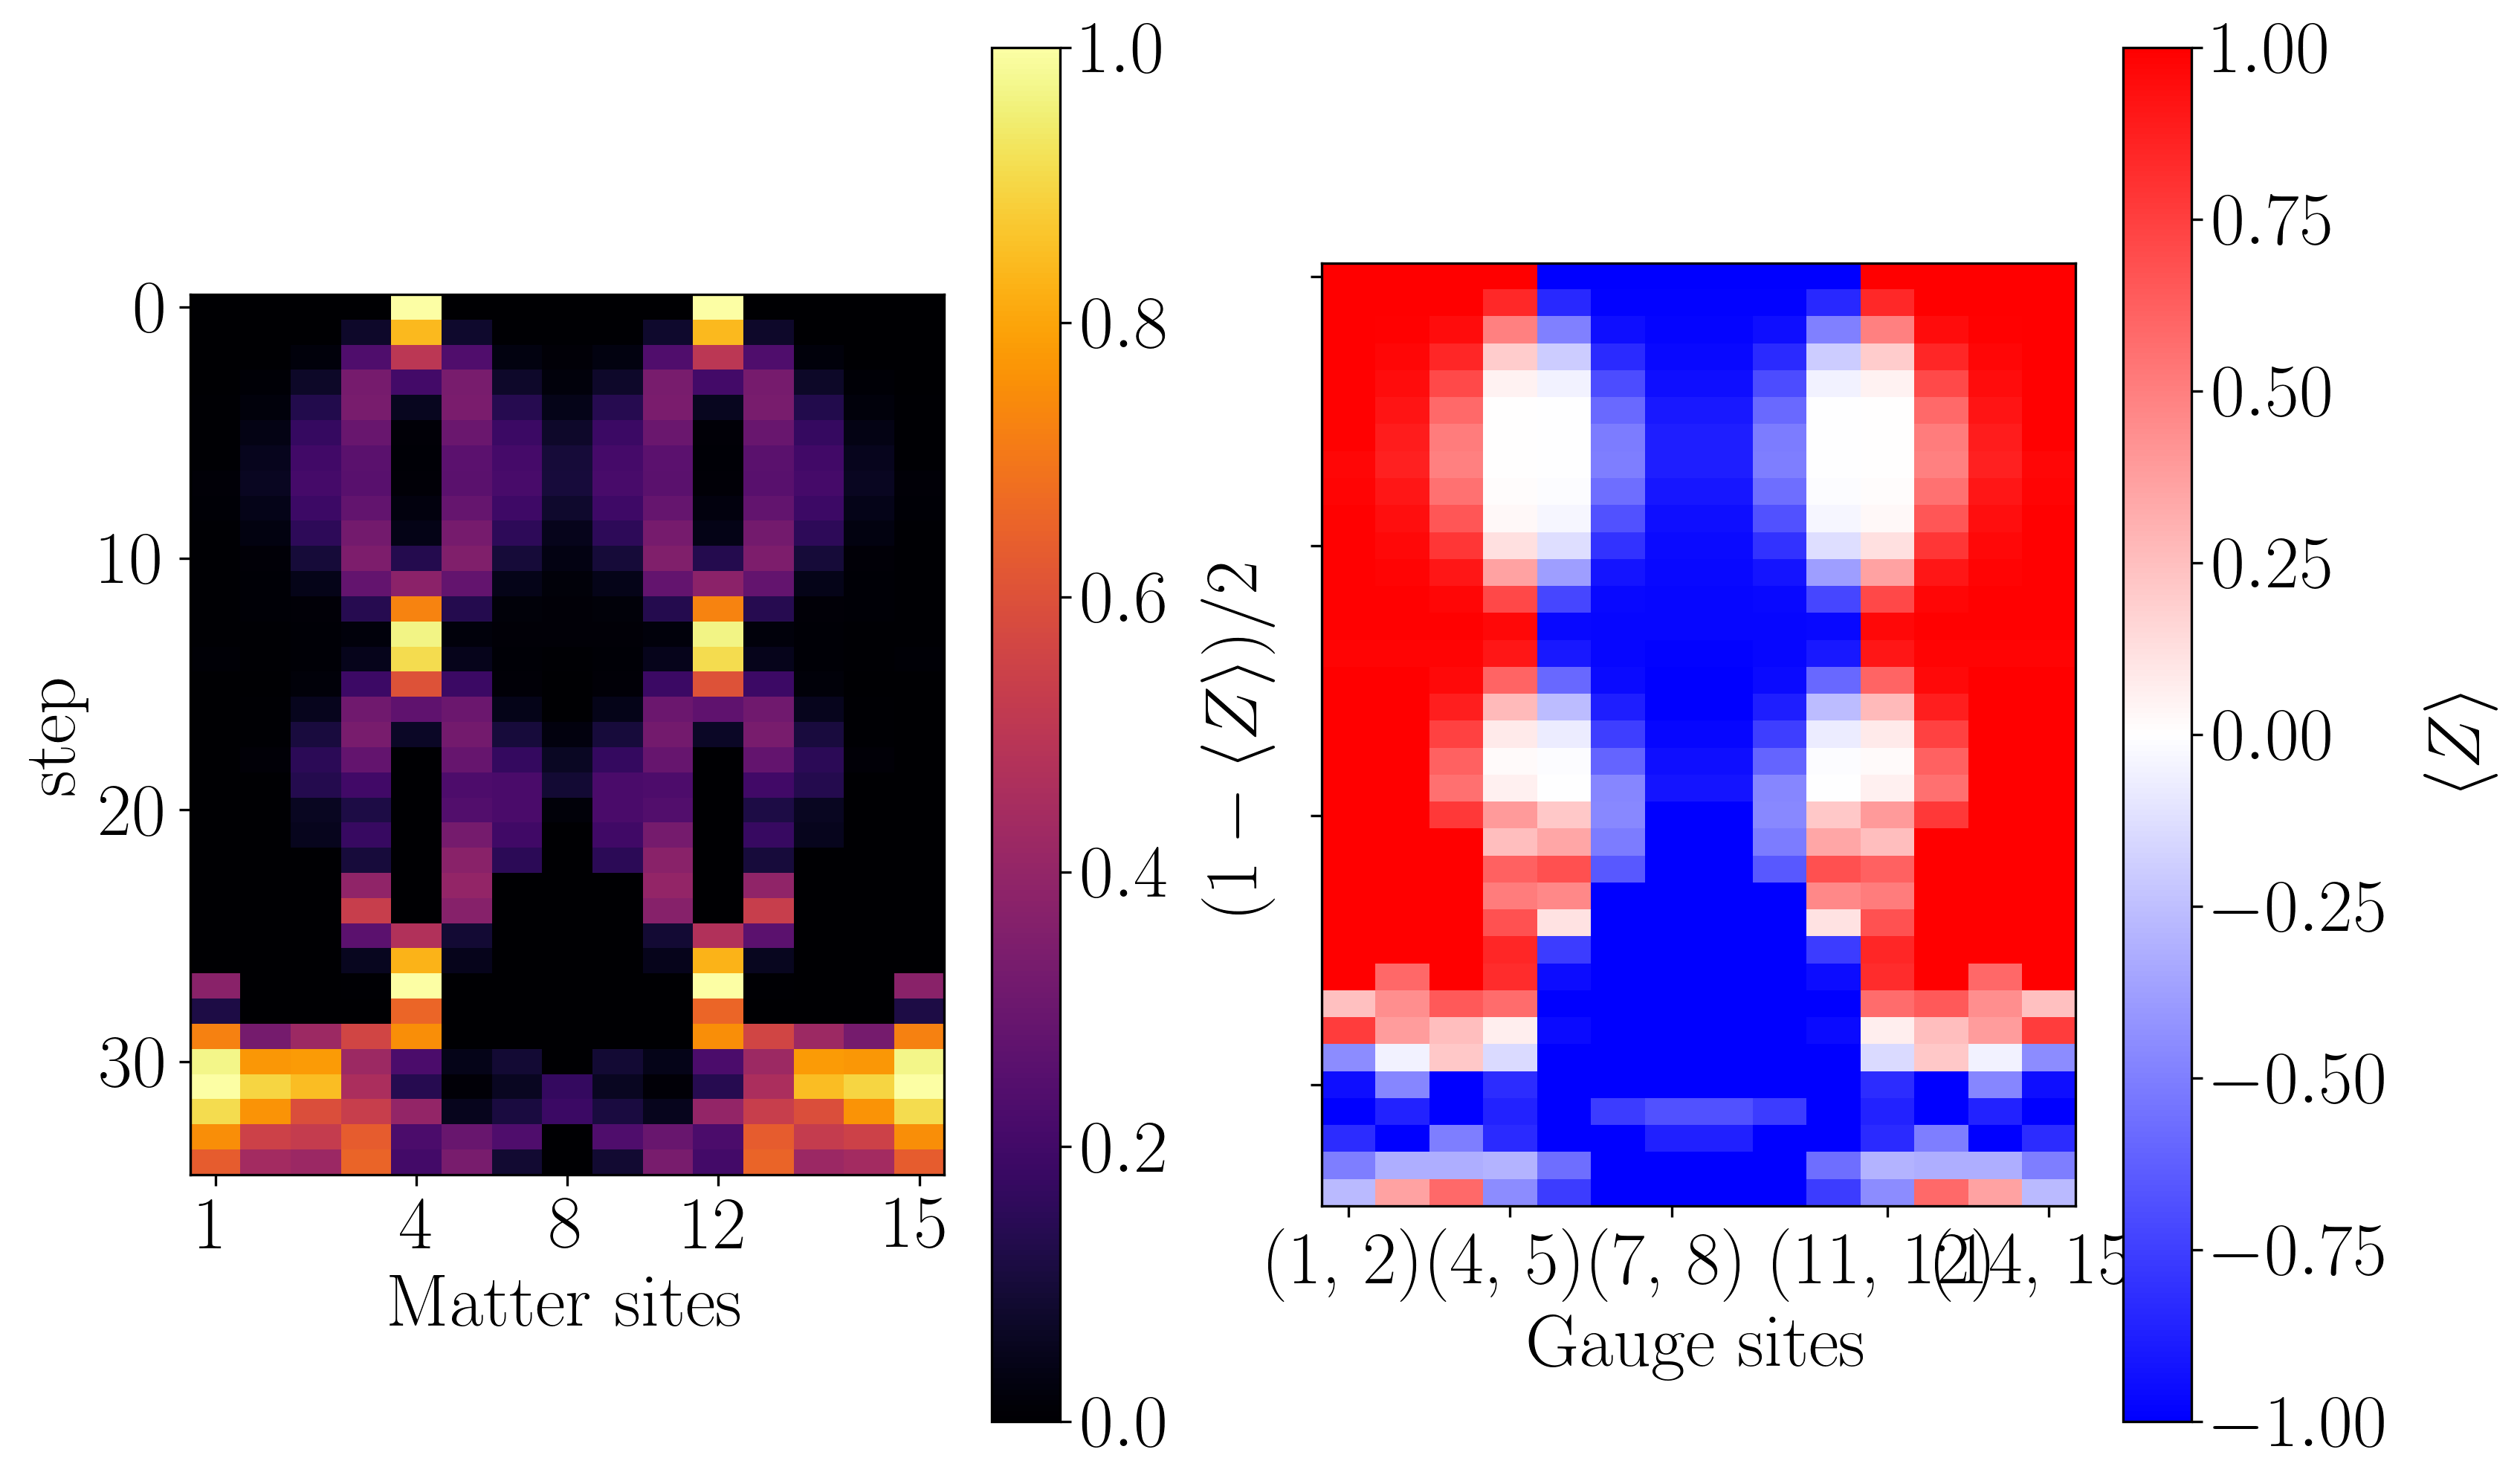

In [5]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix, cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

# Conventional Trotter

In [6]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_ct = 0.29411765
steps_ct = int(np.ceil(final_time/dt_ct))
# comparison_increment_ct = int(dt_ct/dt)
cutoff = 1e-12

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt_ct}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps_ct}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt_ct, steps_ct, x_basis, False, cutoff)
    observable_matrix = np.array(observable_matrix)
    save_site_gauge_observable_matrix(observable_matrix, filepath)
else:
    observable_matrix = load_site_gauge_observable_matrix(filepath)

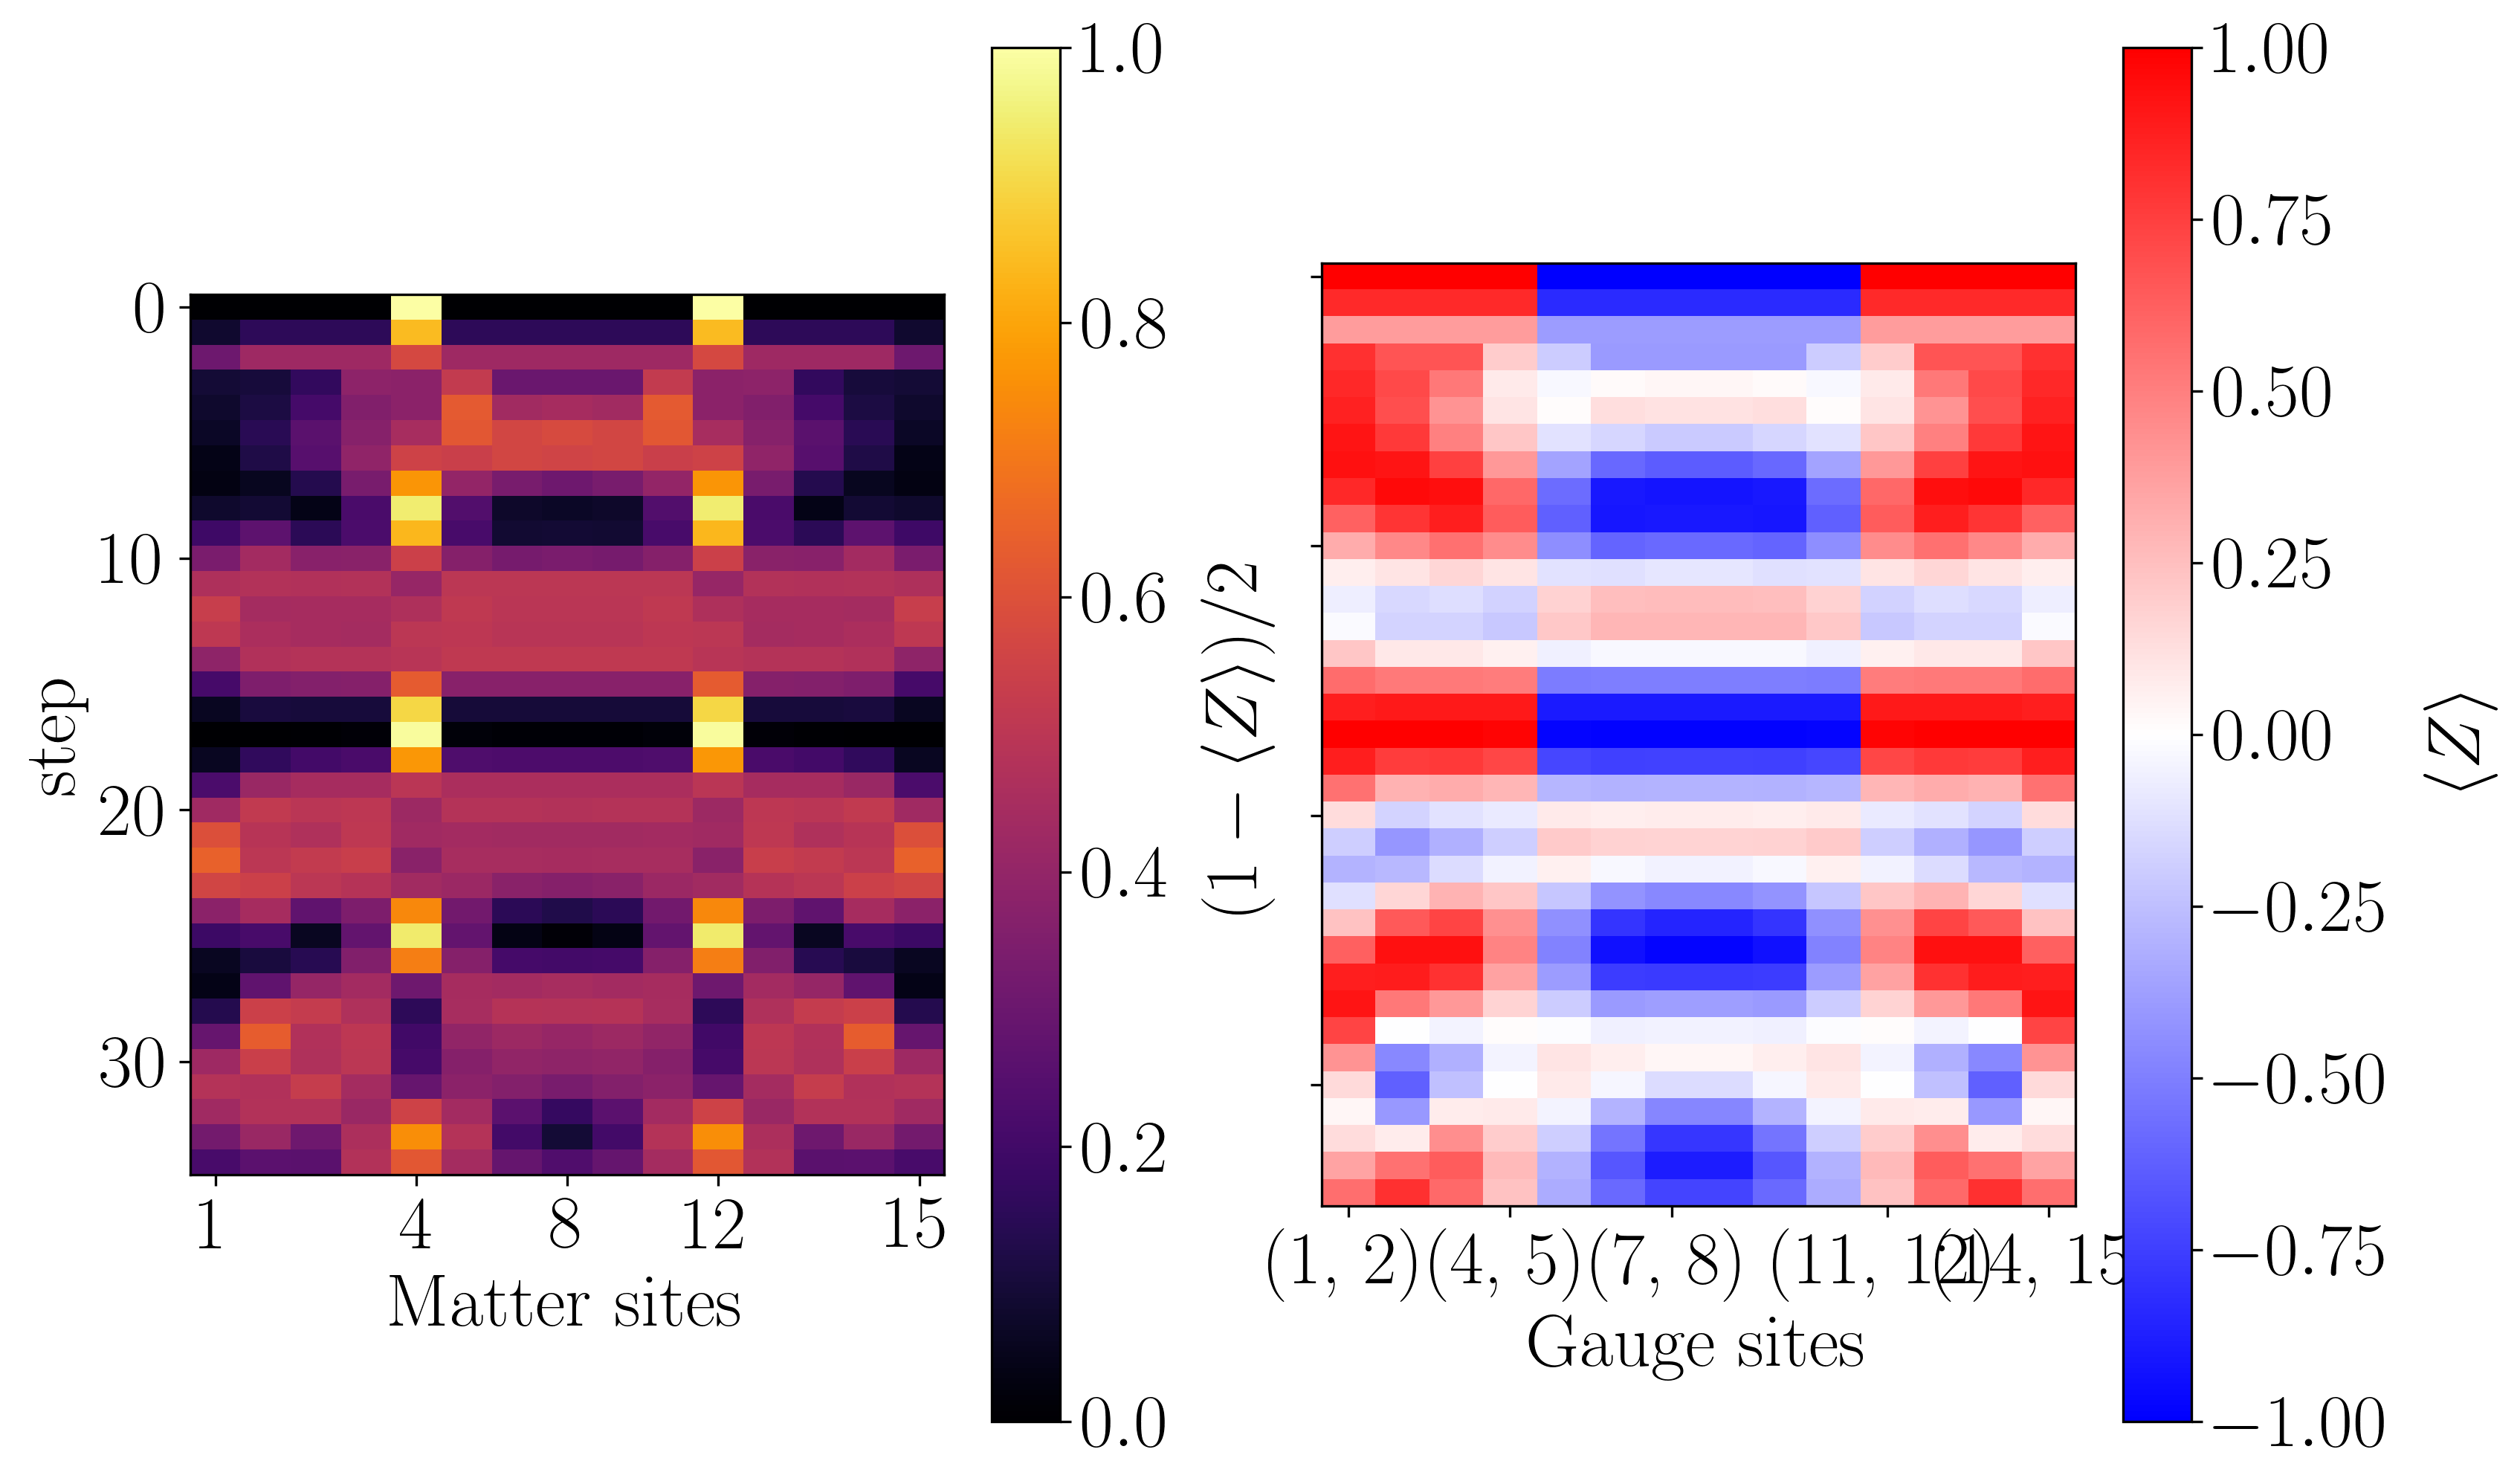

In [7]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix)

# Exactly matching current hardware simulations

In [4]:
L = 15
m = 5
g = 0.8
lamb = 1

final_time = 5

particle_pair_left_position = 4
particle_pair_length = 6

x_basis = False

## (Almost) ground truth

In [17]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

# dt = 0.14705882/20
# dt = 0.007353
dt = 0.01
steps = int(np.ceil(final_time/dt))
# comparison_increment_ct = int(dt_ct/dt)
cutoff = 1e-8

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt, steps, x_basis, False, cutoff)
    observable_matrix = np.array(observable_matrix)
    save_site_gauge_observable_matrix(observable_matrix, filepath)
else:
    observable_matrix = load_site_gauge_observable_matrix(filepath)

Step 500


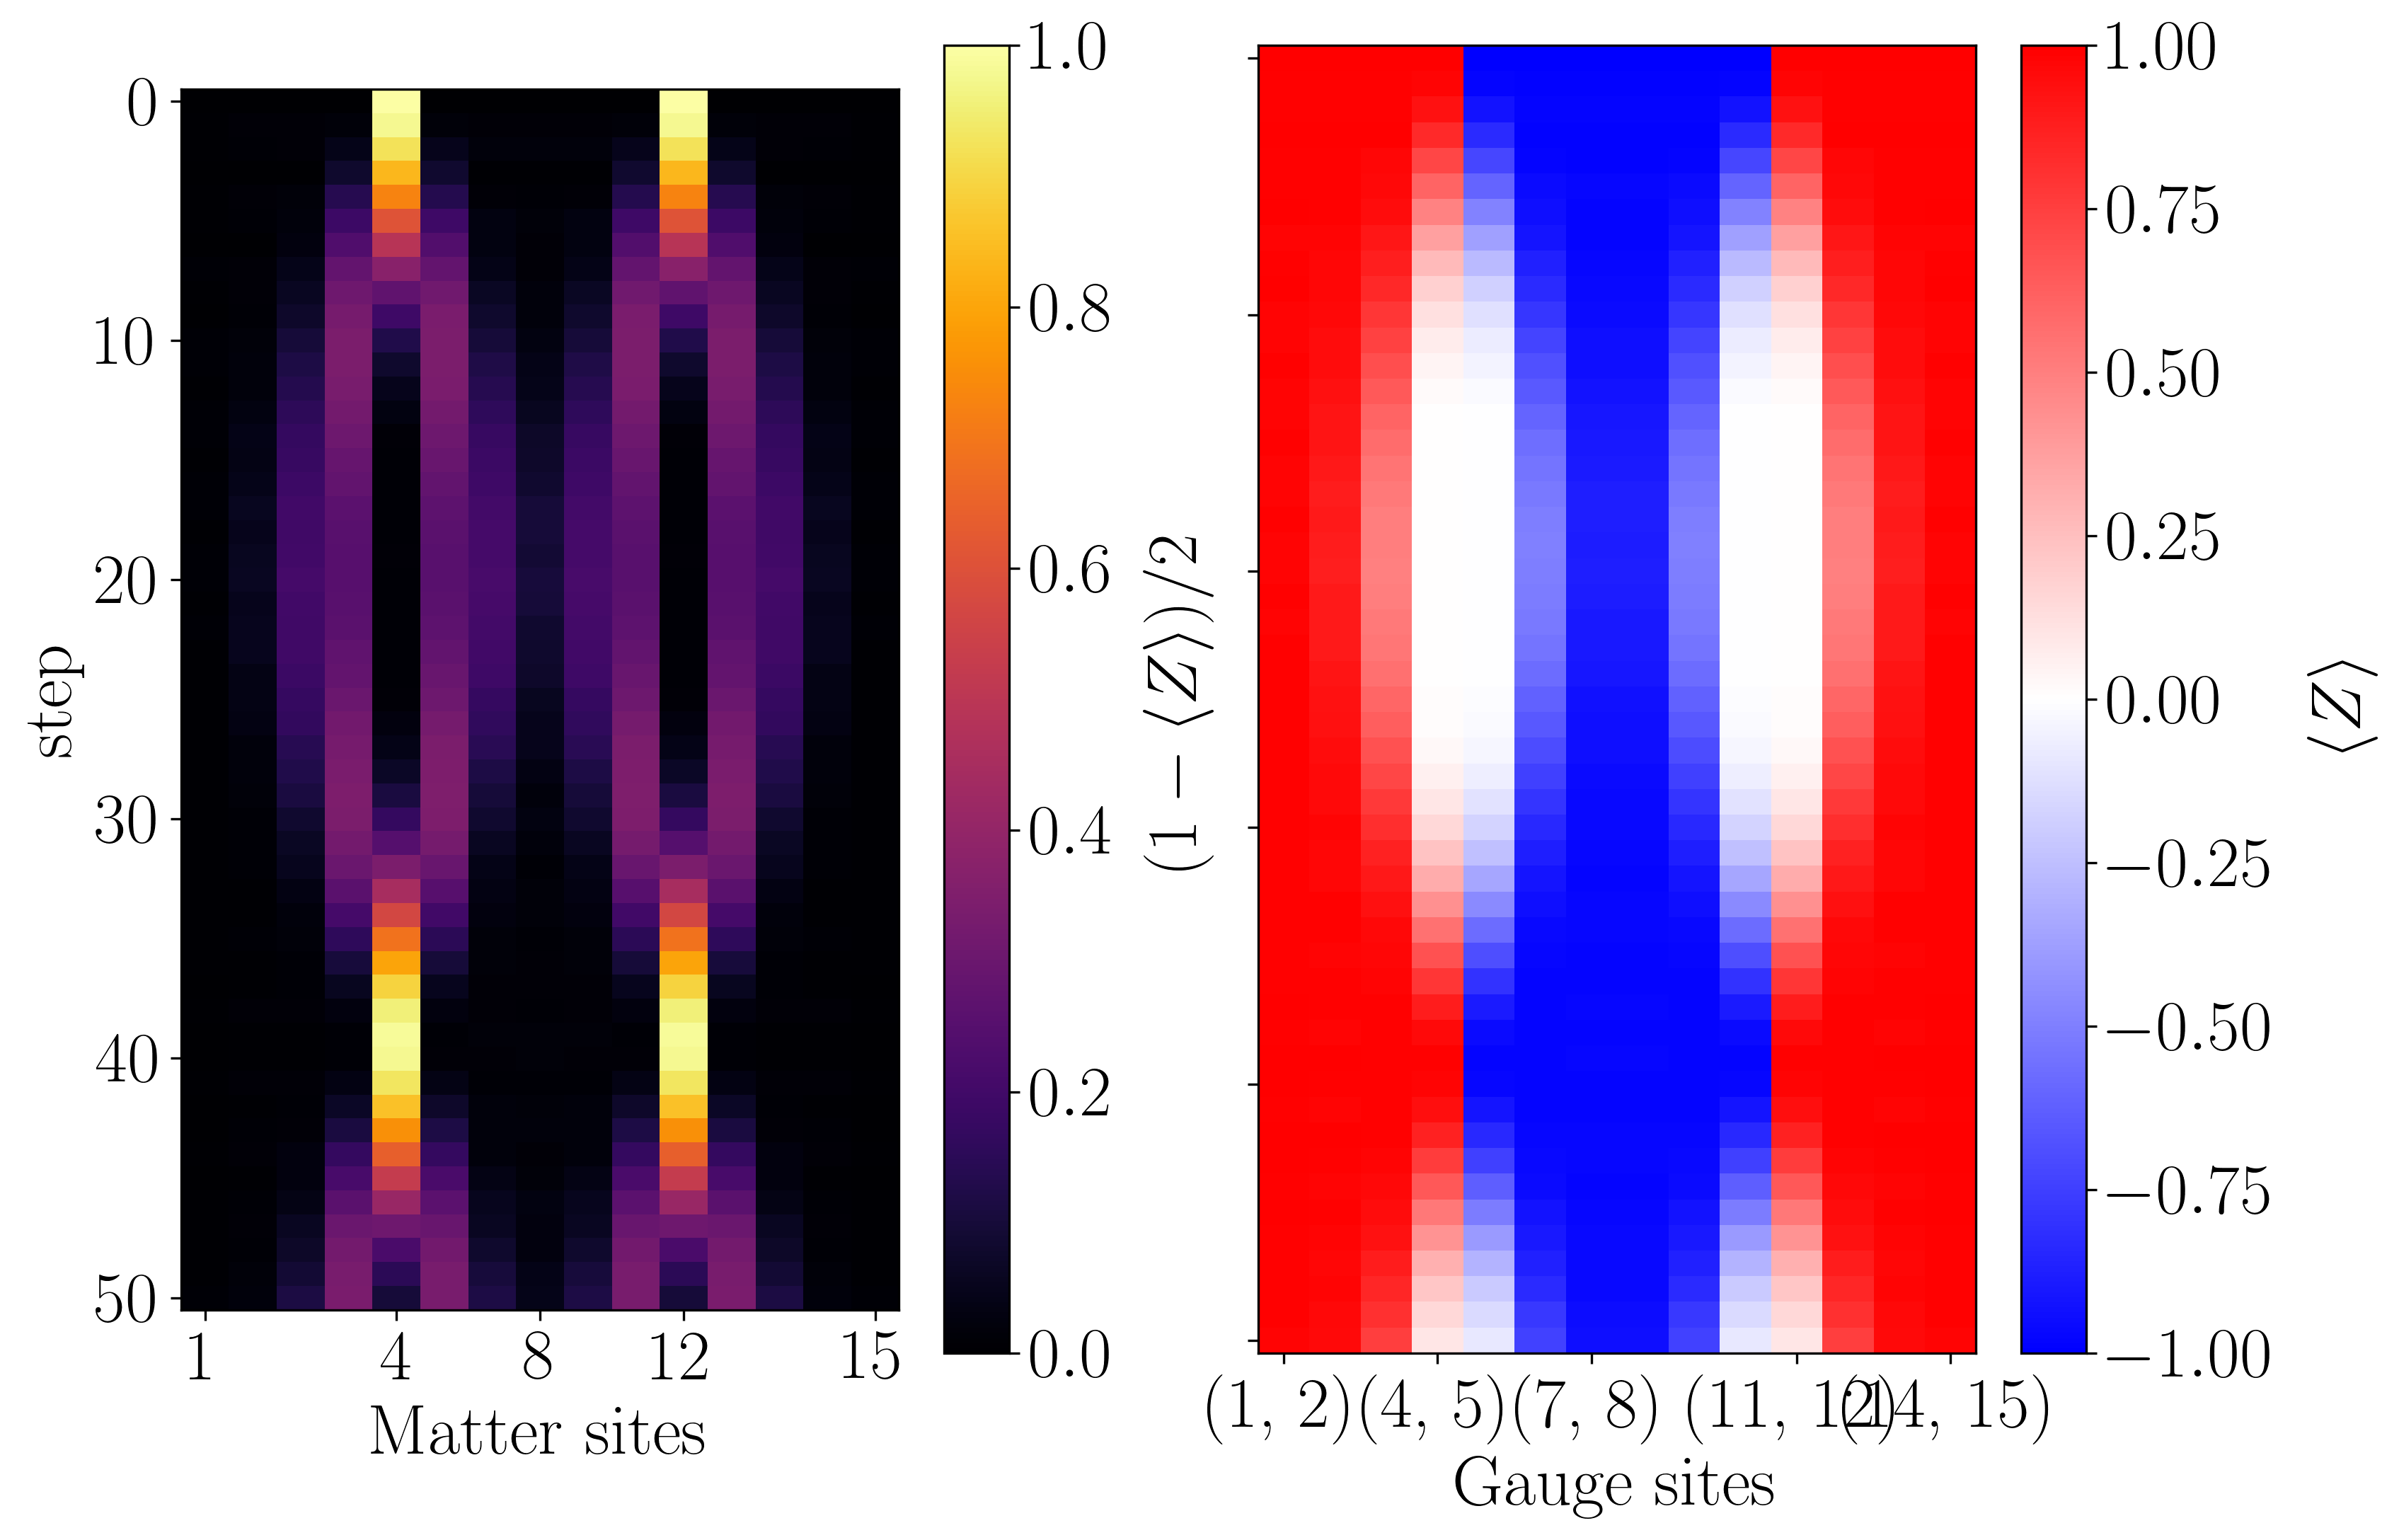

In [20]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix[::10])

## Multiproduct formulas

In [11]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp = 0.14705882
steps_mp = int(np.ceil(final_time/dt_mp))
comparison_increment_mp = int(dt_mp/dt)
multiproduct_lambda = 2
cutoff = 1e-12

filepath = f"Results/tnjulia_multiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_mplamb_{multiproduct_lambda}_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_simulation_2order_first_try(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, multiproduct_lambda, cutoff)
    observable_matrix_mp = np.array(observable_matrix_mp)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp = load_site_gauge_observable_matrix(filepath)

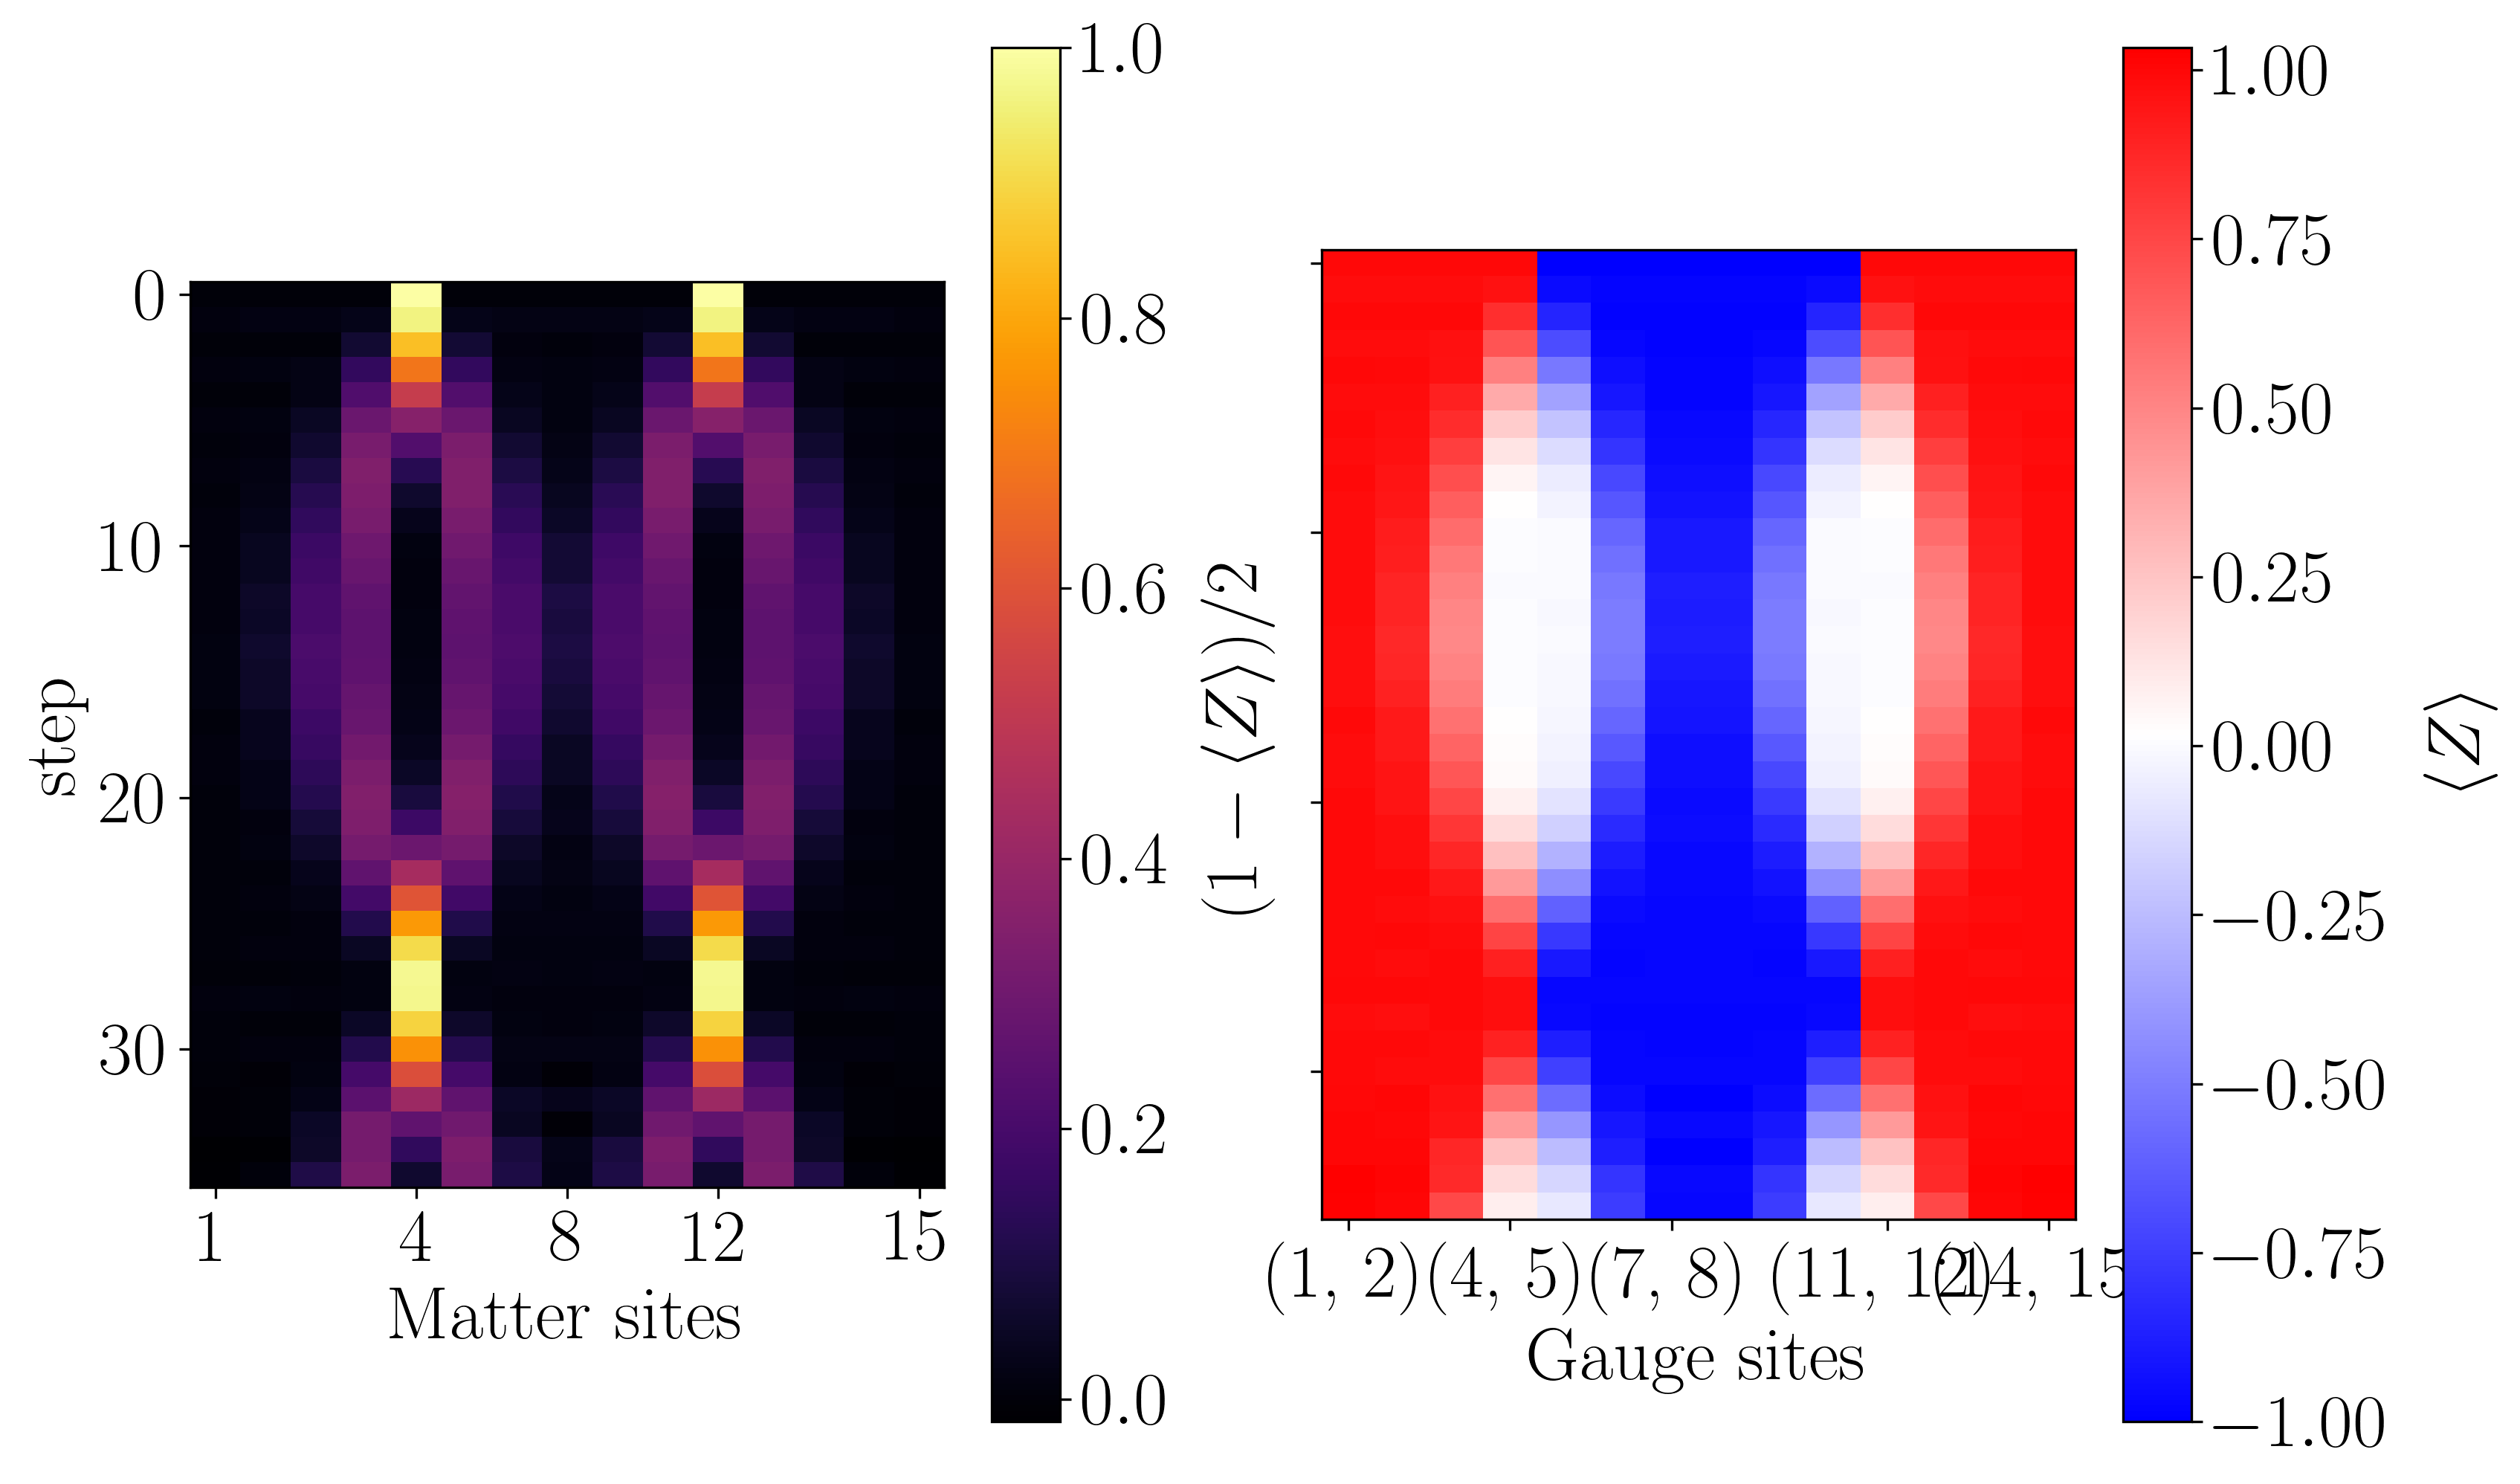

In [12]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp)

In [13]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp_1 = 0.14705882
steps_mp_1 = int(np.ceil(final_time/dt_mp_1))
comparison_increment_mp1 = int(dt_mp_1/dt)
multiproduct_lambda = 1
cutoff = 1e-12

filepath = f"Results/tnjulia_multiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp_1}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_mplamb_{multiproduct_lambda}_xbasis_{x_basis}_steps_{steps_mp_1}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_mp1 = jl.Z2HiggsChainDynamics.multiproduct_simulation_2order_first_try(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp_1, multiproduct_lambda, cutoff)
    observable_matrix_mp1 = np.array(observable_matrix_mp1)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp1 = load_site_gauge_observable_matrix(filepath)

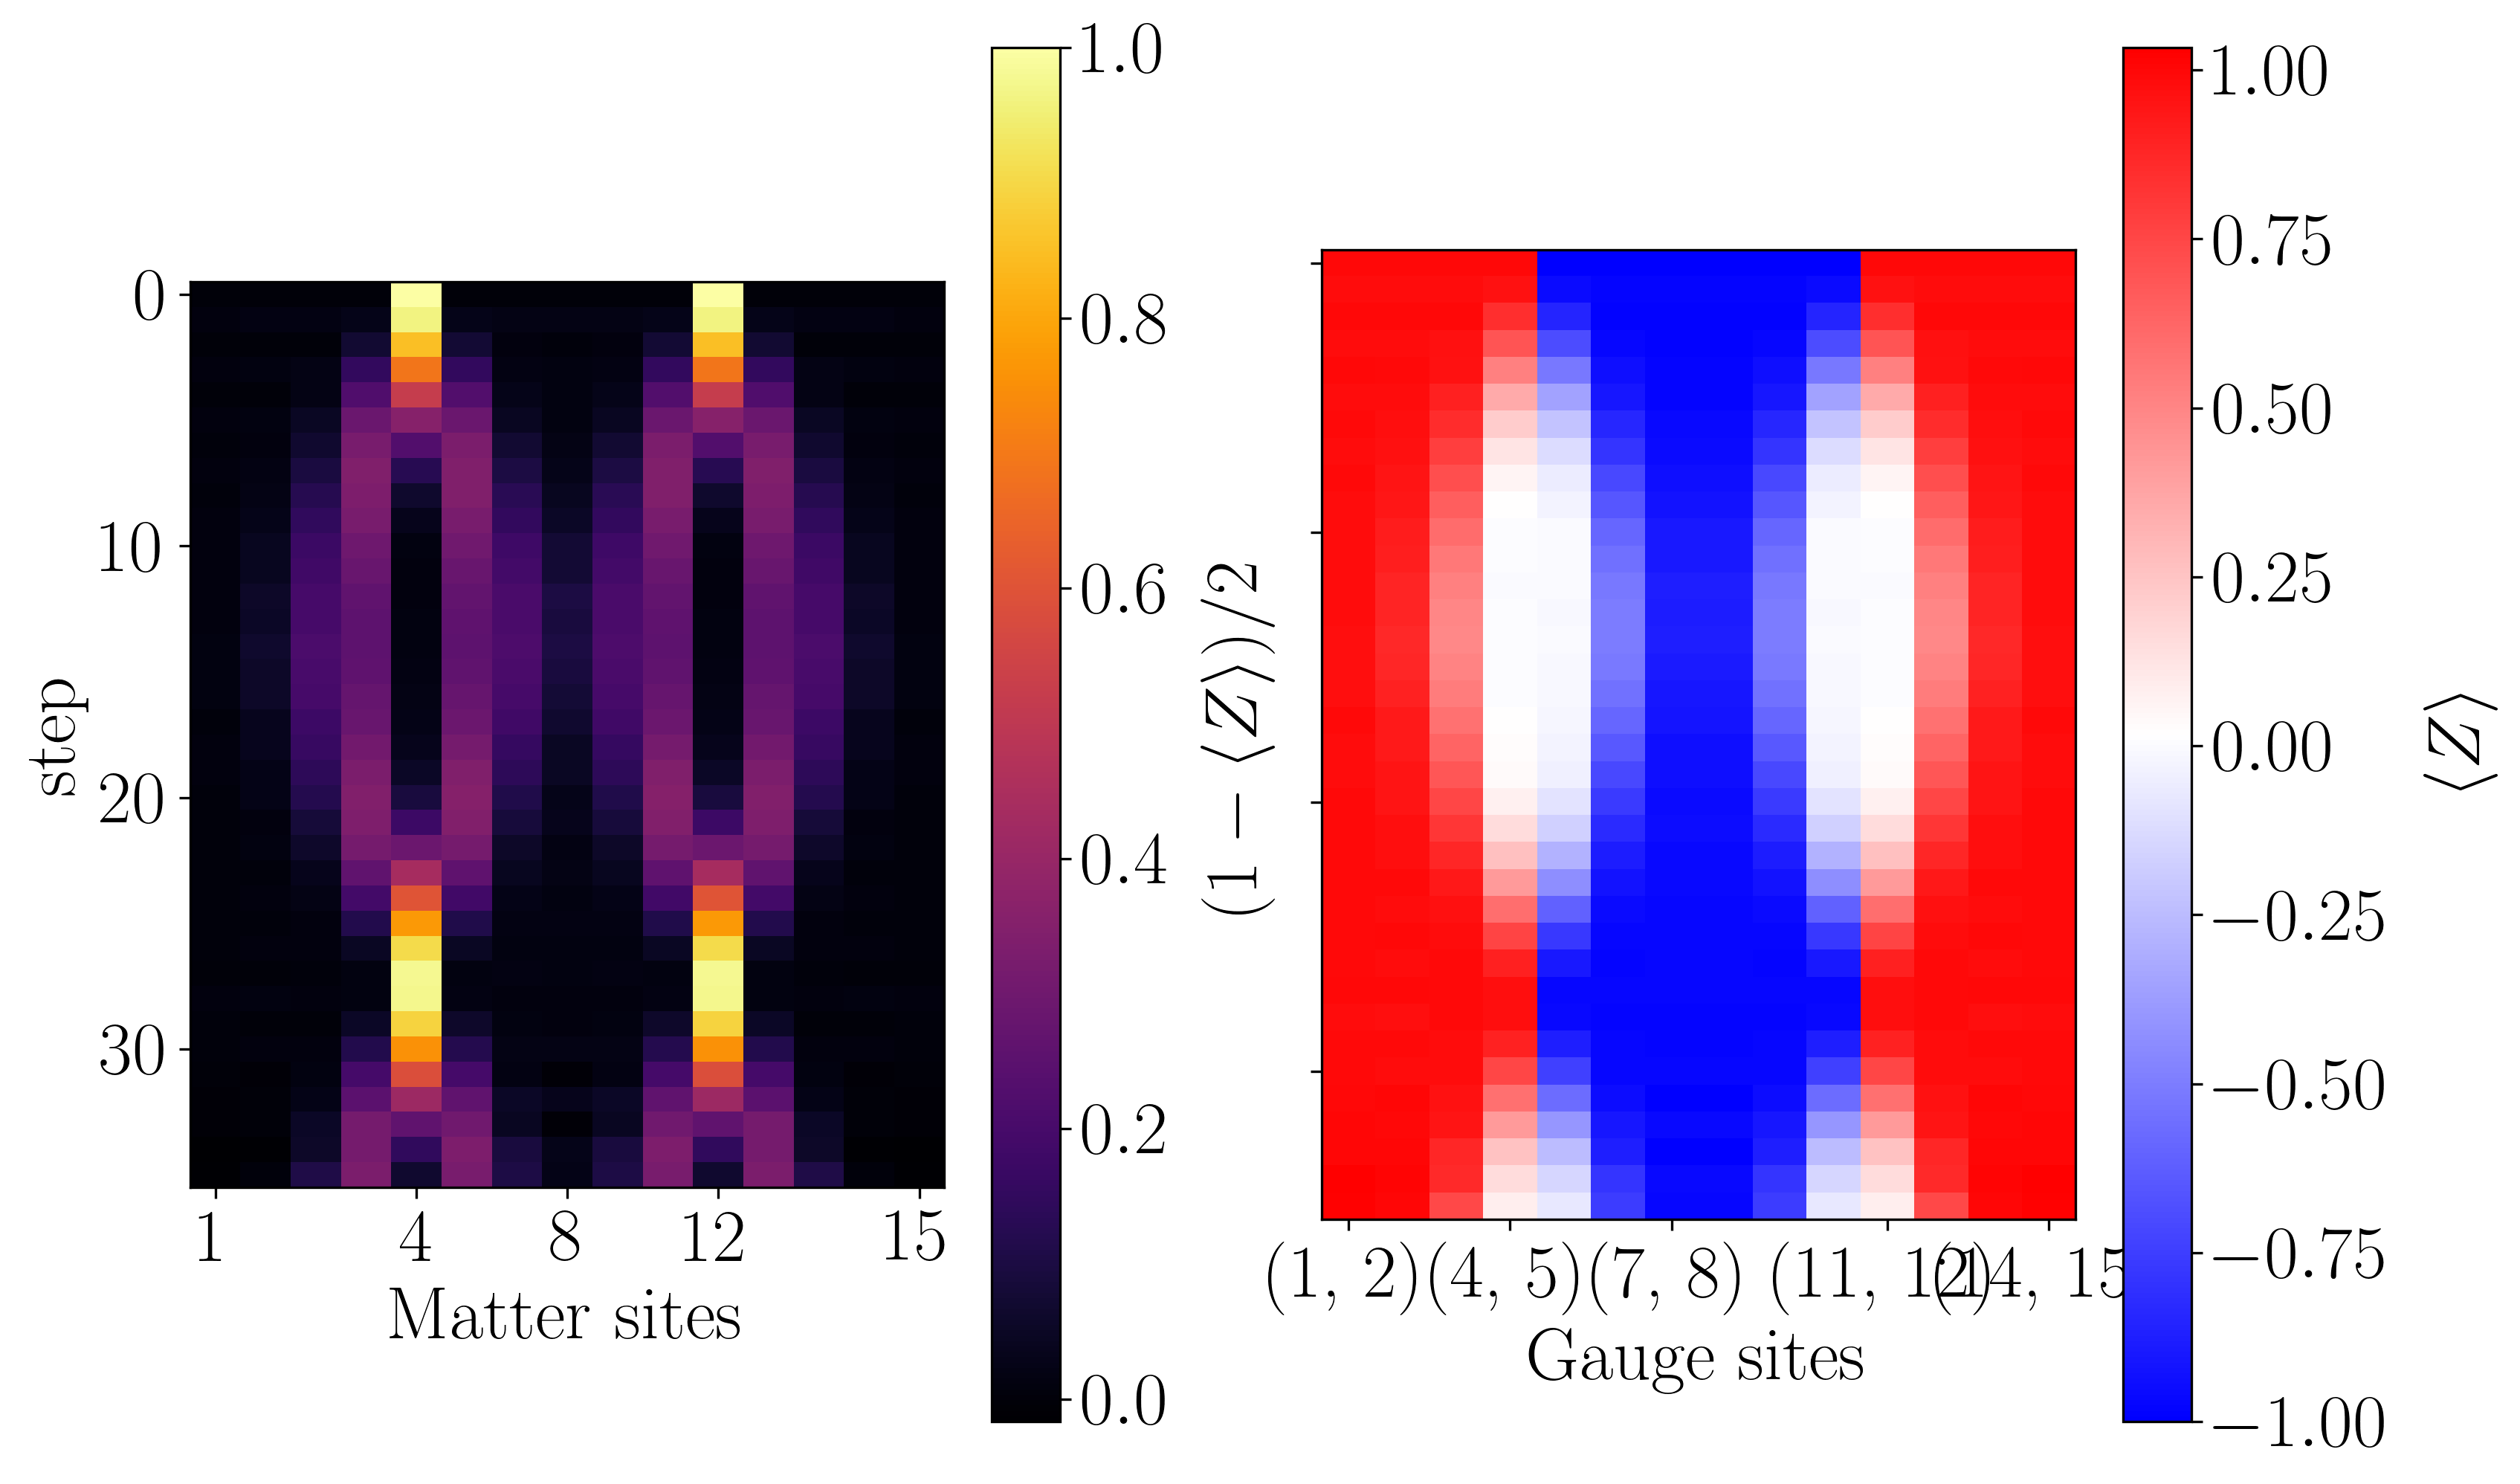

In [14]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp1)

## Conventional Trotter

In [12]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_ct = 0.1
steps_ct = int(np.ceil(final_time/dt_ct))
# comparison_increment_ct = int(dt_ct/dt)
cutoff = 1e-12

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt_ct}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps_ct}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_ct = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt_ct, steps_ct, x_basis, False, cutoff)
    observable_matrix_ct = np.array(observable_matrix_ct)
    save_site_gauge_observable_matrix(observable_matrix_ct, filepath)
else:
    observable_matrix_ct = load_site_gauge_observable_matrix(filepath)

Step 50


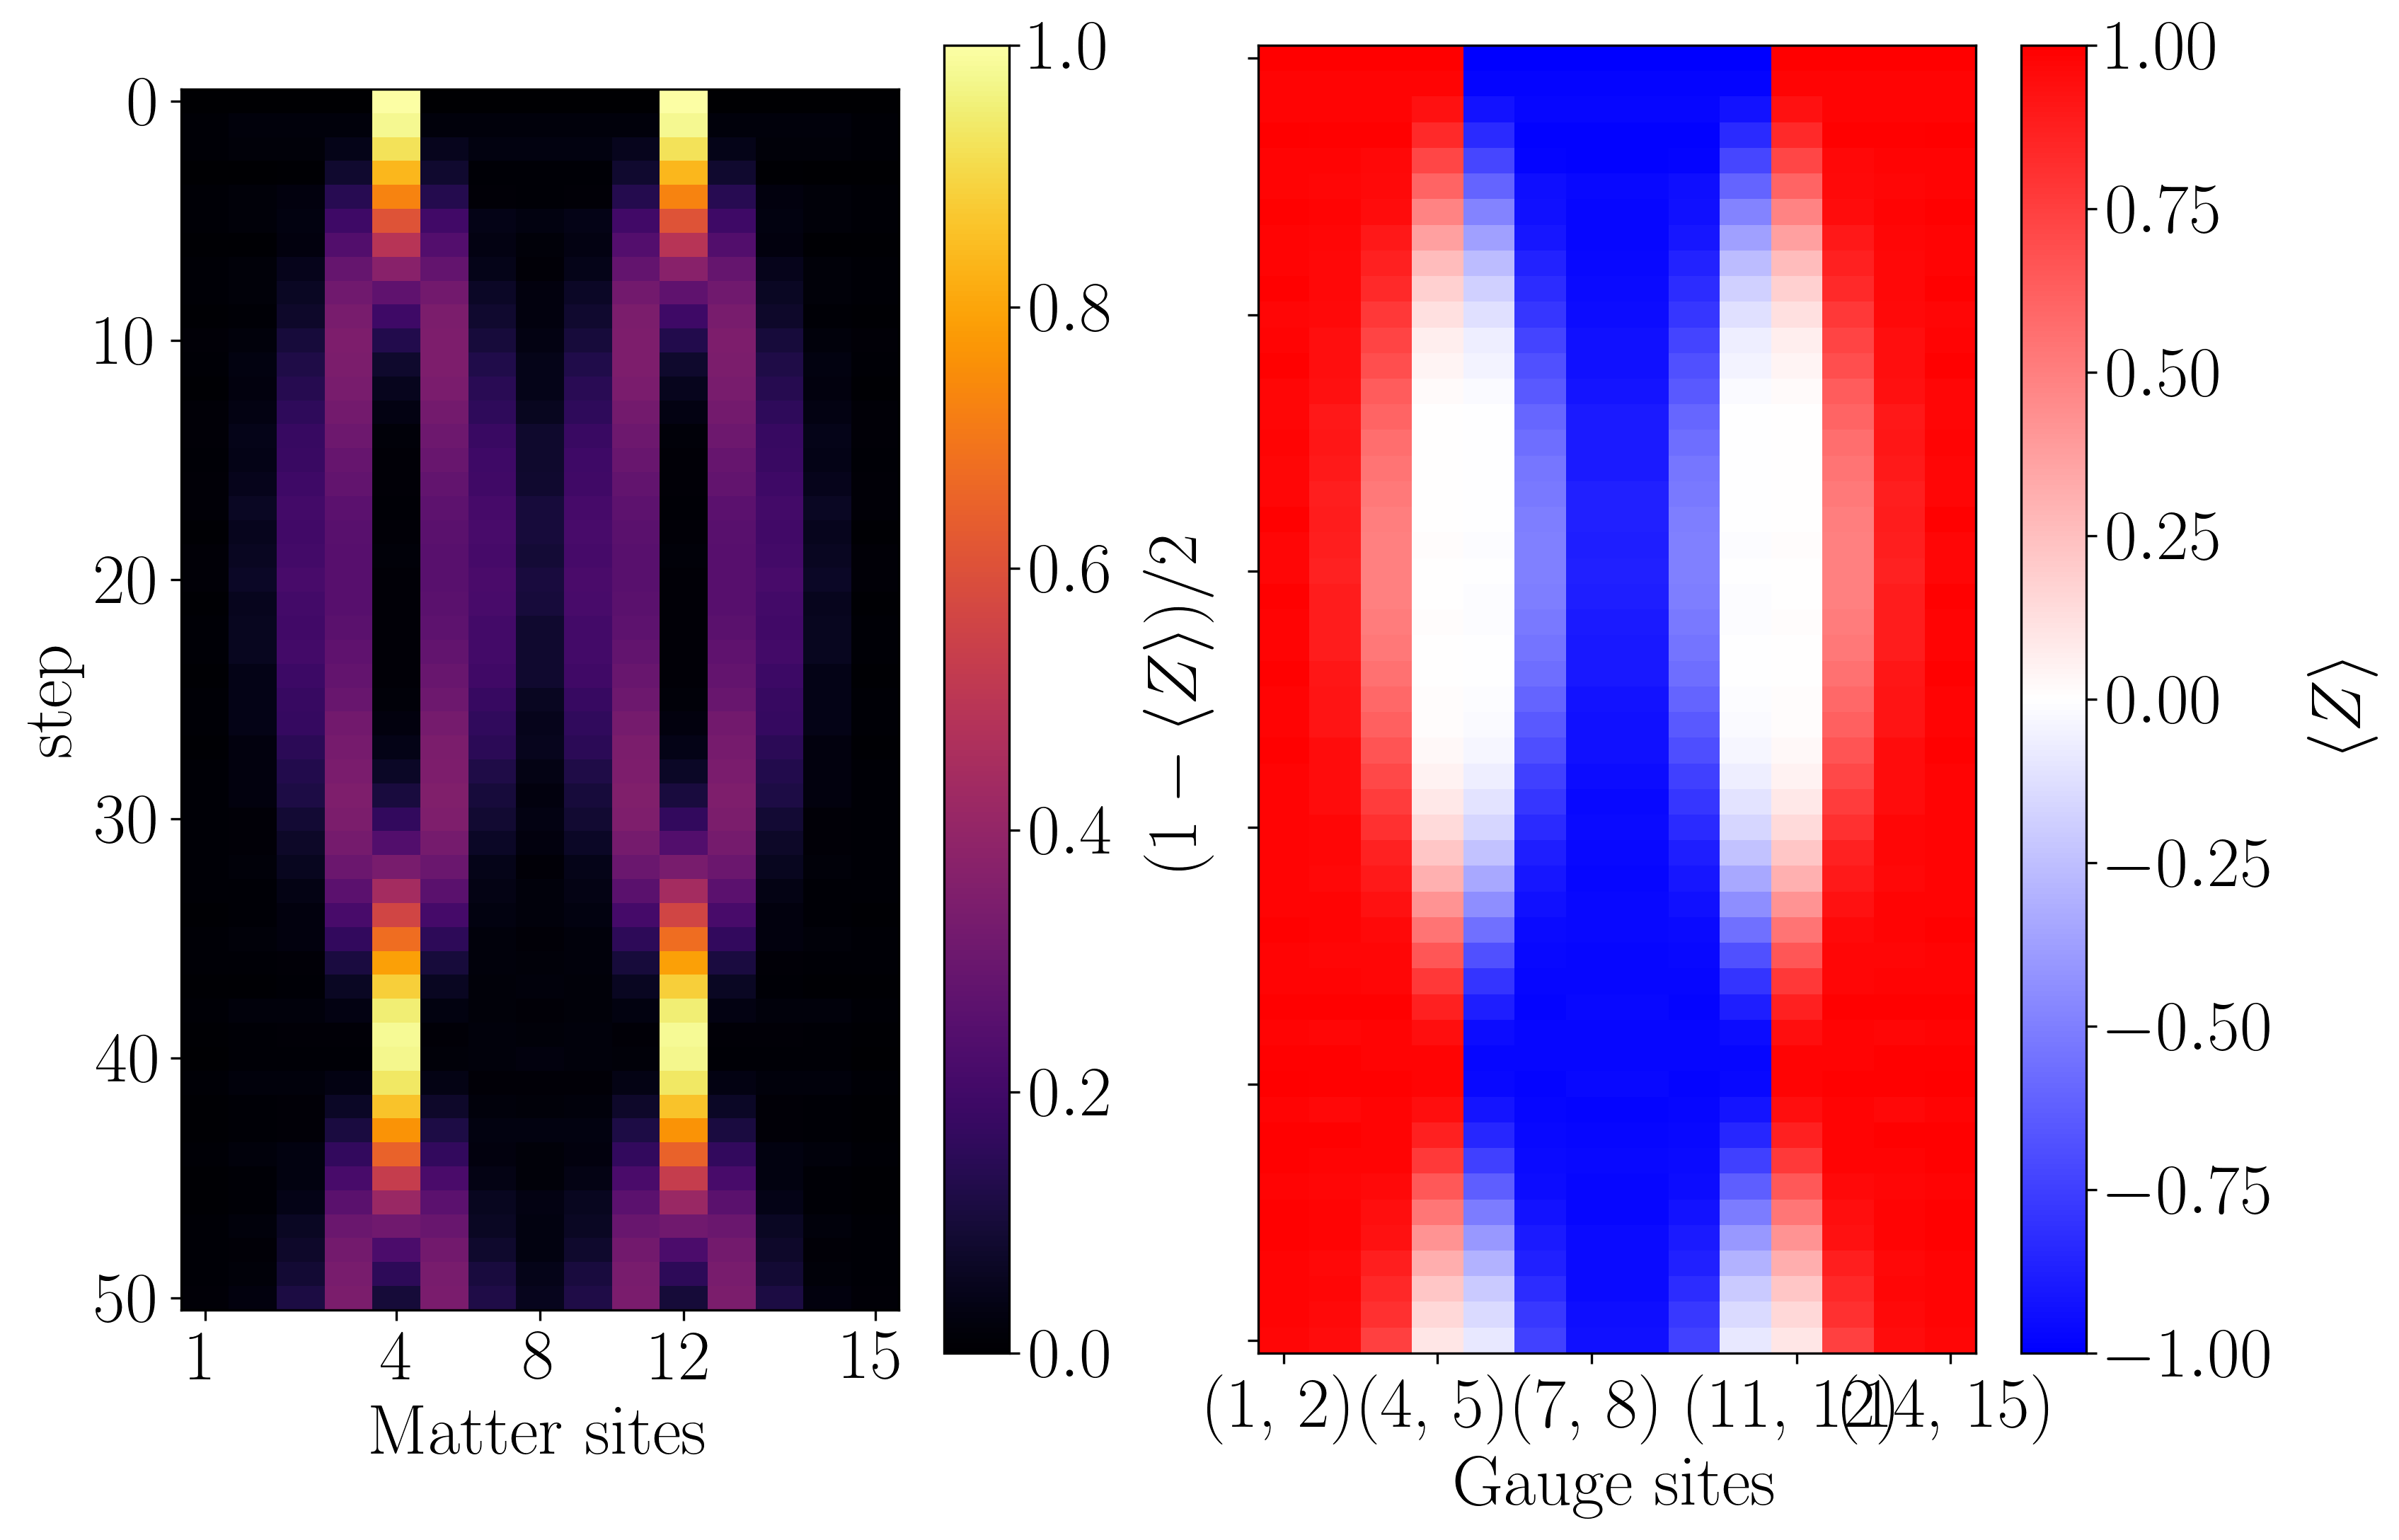

In [13]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_ct)

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_ct_1 = 0.29411765
steps_ct_1 = int(np.ceil(final_time/dt_ct_1))
# comparison_increment_ct = int(dt_ct_1/dt)
cutoff = 1e-12

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt_ct_1}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps_ct_1}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_ct_1 = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt_ct_1, steps_ct_1, x_basis, False, cutoff)
    observable_matrix_ct_1 = np.array(observable_matrix_ct_1)
    save_site_gauge_observable_matrix(observable_matrix_ct_1, filepath)
else:
    observable_matrix_ct_1 = load_site_gauge_observable_matrix(filepath)

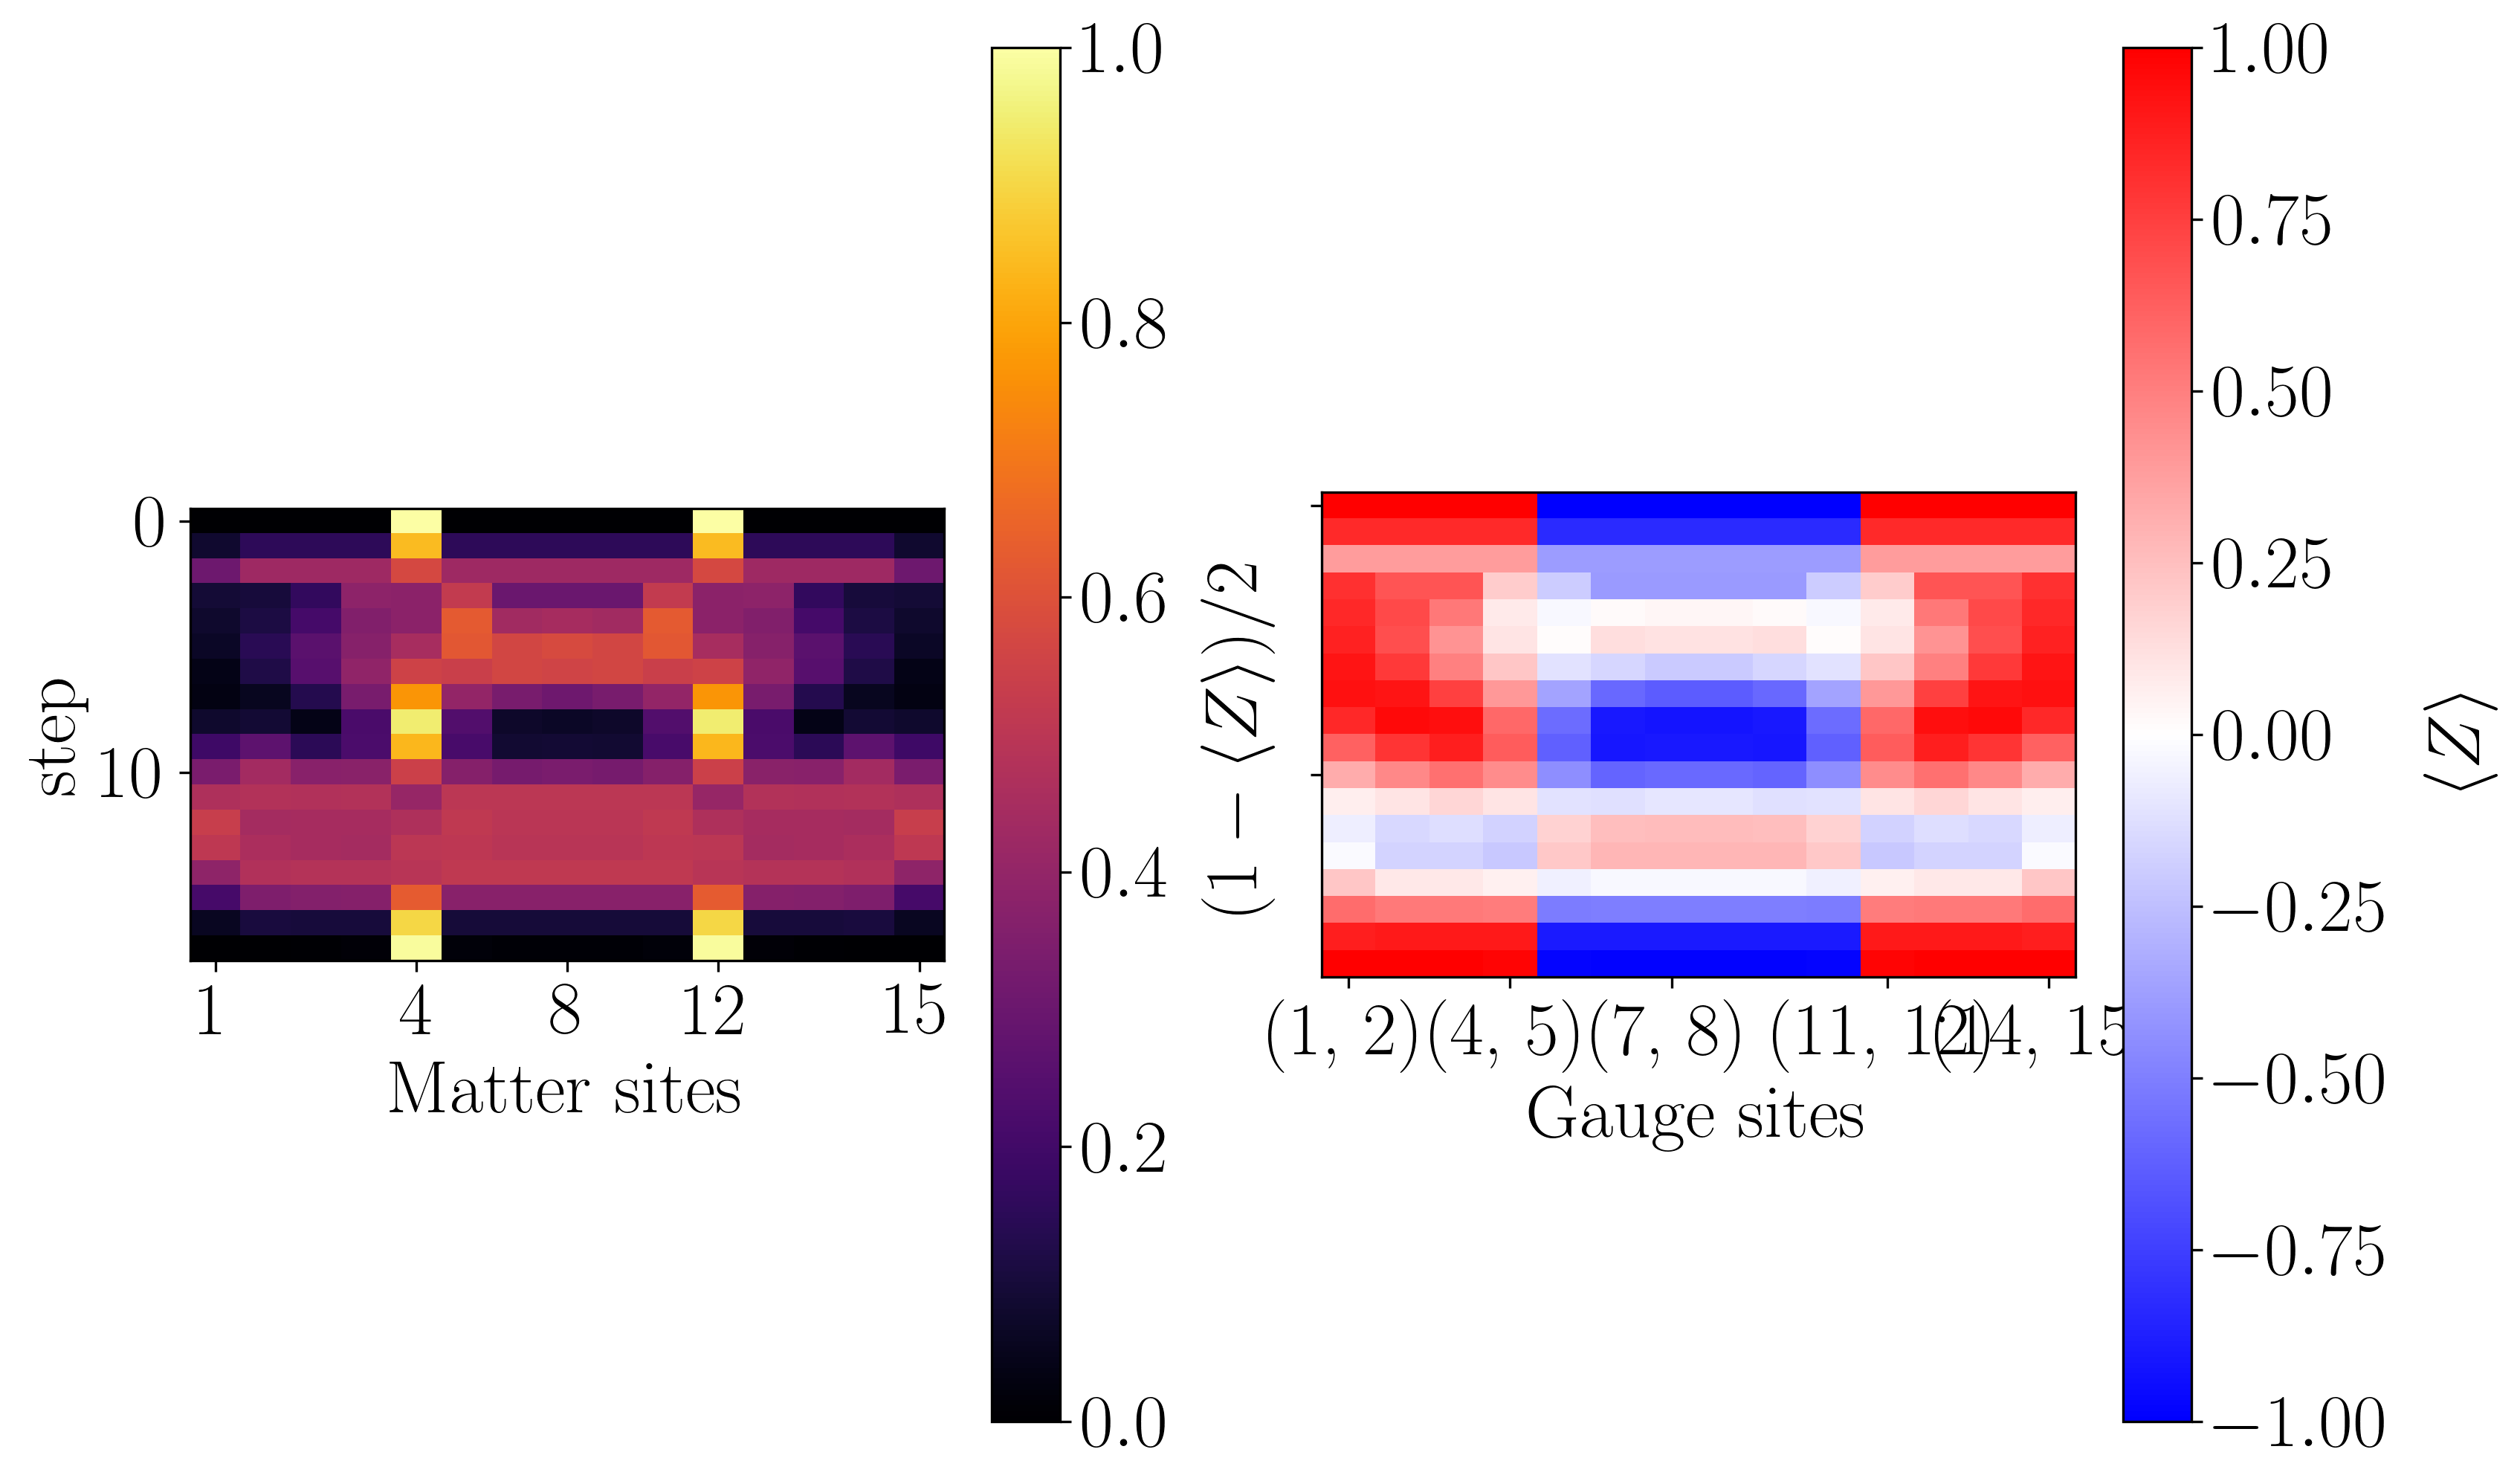

In [18]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_ct_1)

## Comparison

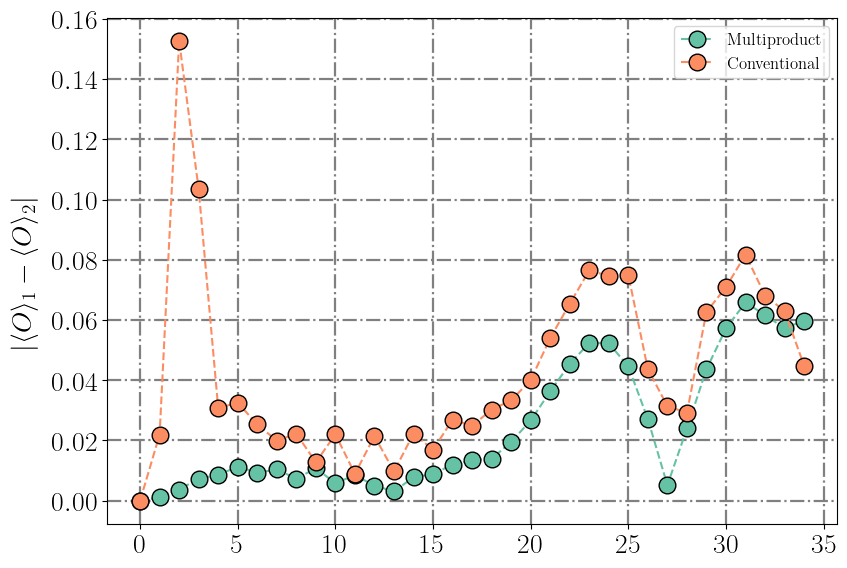

In [19]:
from utils.plotting import plot_mean_deviations

# x_ticks = [
#     np.arange(0, steps+1, (steps)//4),
#     np.linspace(0, final_time, 5)
# ]

comparison_increment = 20

plot_mean_deviations([observable_matrix_mp[:-1], observable_matrix_ct[:-1]], [observable_matrix[::comparison_increment]]*2, labels=["Multiproduct", "Conventional"])

## New approach

In [14]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

# dt_mp = 0.14705882
dt_mp = 0.1
steps_mp = int(np.ceil(final_time/dt_mp))
# comparison_increment_mp = int(dt_mp/dt)
min_k_max = 3
cutoff = 1e-12

filepath = f"Results/tnjulia_wcmultiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_dtmaxk_minkmax_{min_k_max}_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = True

jl.seval(f"max_k_func(t) = MultiProductF.dt_limited_max_k(t, {dt_mp}; min_k_max={min_k_max})")

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    
    # observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_particle_pair_simulation_2order(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, jl.max_k_func, cutoff)
    
    ks, coefficients, _ = jl.MultiProductF.search_mpf_parameters_ccost(1, 3, 2, 35, jl.MultiProductF.k_a_onenorm_cost)
    base_ks = jl.copy(ks[0])
    base_coefficients = jl.copy(coefficients[0, :])
    observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_particle_pair_simulation_2order(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, dt_mp, base_ks, base_coefficients, cutoff)

    observable_matrix_mp = np.array(observable_matrix_mp)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp = load_site_gauge_observable_matrix(filepath)

Step 50

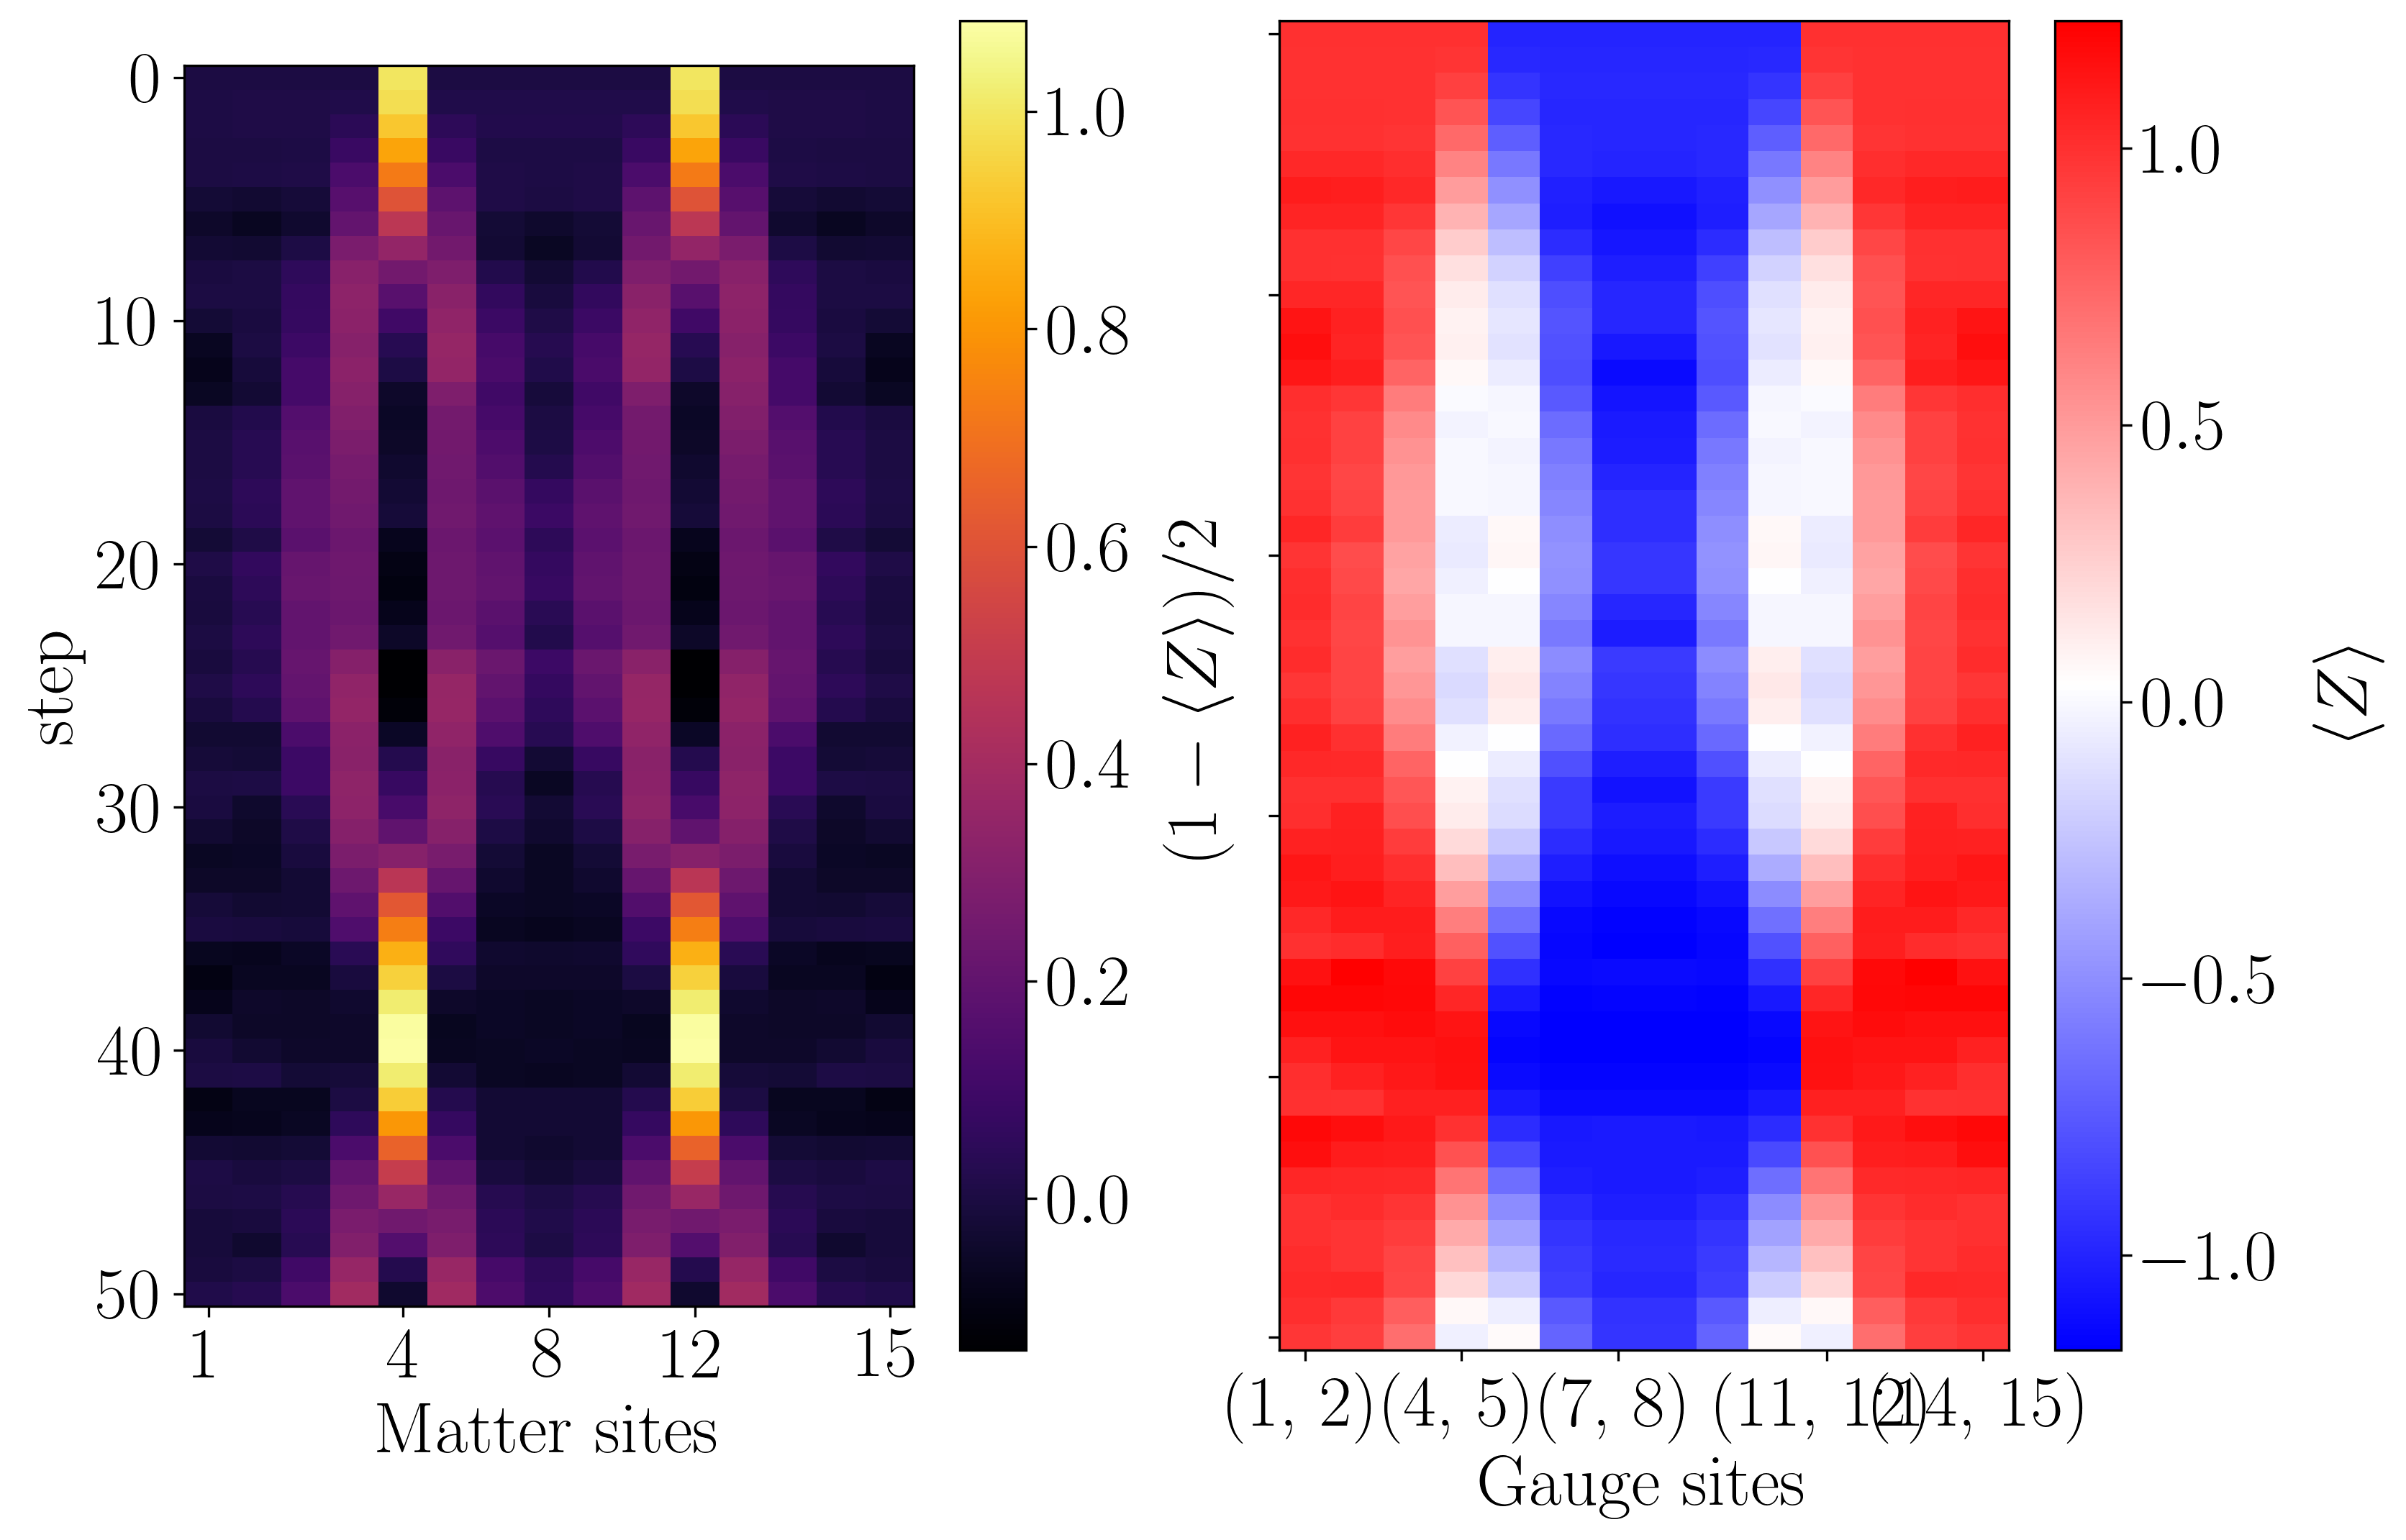

In [15]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp)

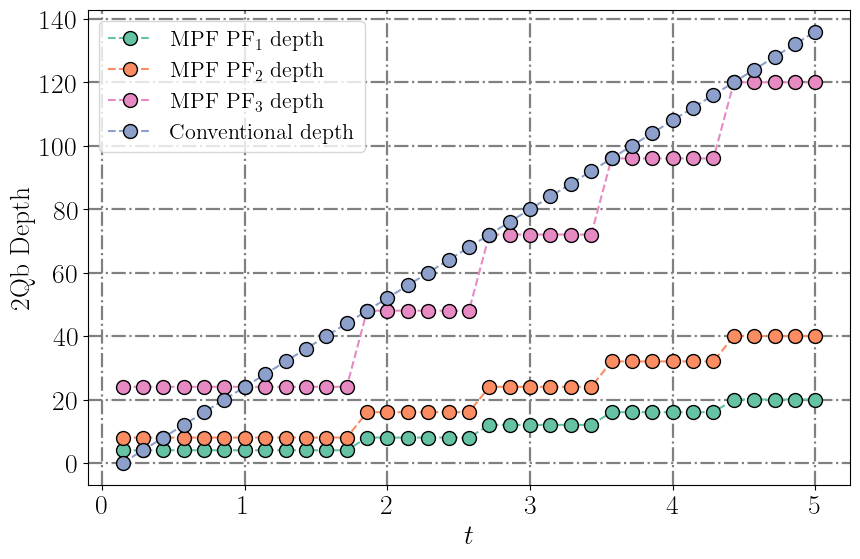

In [11]:
import matplotlib.pyplot as plt
import numpy as np

filepath_depth = "MPF 1D depth.png"
filepath_coeff = "MPF 1D coeffs.png"

times_arr = np.linspace(0, final_time, steps_mp+1)
ks = np.zeros((steps_mp, 3))
coefficients = np.zeros((steps_mp, 3))
for i, t in enumerate(times_arr[1::]):
    this_ks, this_coefficients, _ = jl.MultiProductF.search_mpf_parameters_ccost(t, 3, 2, jl.max_k_func, jl.MultiProductF.a_onenorm_cost)
    # ks[i, :] = np.array(this_ks)[0]
    # coefficients[i, :] = np.array(this_coefficients)[0]
    ks[i, :] = np.array(base_ks) * ((t / dt_mp) // base_ks[-1] if ((t / dt_mp) // base_ks[-1]) > 0 else 1)

min_depth_mpf = 4*np.min(ks, axis=1)
max_depth_mpf = 4*np.max(ks, axis=1)

conventional_depth = 4*(times_arr[1::] // dt_mp)

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
cmap = plt.get_cmap("Set2")

plt.plot(times_arr[1::], 4*ks[:, 0], "o--", markersize=10, markeredgecolor="black", color=cmap(0), label=r"MPF $\mathrm{PF}_1$ depth")
plt.plot(times_arr[1::], 4*ks[:, 1], "o--", color=cmap(1), markersize=10, markeredgecolor="black", label=r"MPF $\mathrm{PF}_2$ depth")
plt.plot(times_arr[1::], 4*ks[:, 2], "o--", color=cmap(3), markersize=10, markeredgecolor="black", label=r"MPF $\mathrm{PF}_3$ depth")
plt.plot(times_arr[1::], conventional_depth, "o--", color=cmap(2), markersize=10, markeredgecolor="black", label="Conventional depth")
plt.xlabel(r"$t$")
plt.ylabel("2Qb Depth")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.legend(loc="best", fontsize=16)
plt.tight_layout()
if filepath_depth:
    plt.savefig(filepath_depth, dpi=300, facecolor="none")
plt.show()

# fig, ax = plt.subplots(figsize=[9, 6])
# cmap = plt.get_cmap("Set2")

# plt.plot(times_arr[1::], coefficients[:, 0], "o--", markersize=10, markeredgecolor="black", color=cmap(0), label=r"$c_1$")
# plt.plot(times_arr[1::], coefficients[:, 1], "o--", markersize=10, markeredgecolor="black", color=cmap(1), label=r"$c_2$")
# plt.plot(times_arr[1::], coefficients[:, 2], "o--", markersize=10, markeredgecolor="black", color=cmap(2), label=r"$c_3$")
# plt.xlabel(r"$t$")
# plt.ylabel(r"$c_i$")
# plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
# plt.legend(loc="best", fontsize=16)
# plt.tight_layout()
# if filepath_coeff:
#     plt.savefig(filepath_coeff, dpi=300, facecolor="none")
# plt.show()

In [16]:
from utils.plotting import plot_mean_deviations

# x_ticks = [
#     np.arange(0, steps+1, (steps)//4),
#     np.linspace(0, final_time, 5)
# ]

comparison_increment = 20

plot_mean_deviations([observable_matrix_mp[:-1], observable_matrix_ct[:-1]], [observable_matrix[::comparison_increment]]*2, labels=["Multiproduct", "Conventional"])

ValueError: Observable matrices must have the same shape

# Longer times

In [4]:
L = 15
m = 5
g = 0.8
lamb = 1

final_time = 5*2

particle_pair_left_position = 4
particle_pair_length = 6

x_basis = False

## Multiproduct

In [23]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp = 0.14705882*2
steps_mp = int(np.ceil(final_time/dt_mp))
comparison_increment_mp = int(dt_mp/dt)
multiproduct_lambda = 2
cutoff = 1e-12

filepath = f"Results/tnjulia_multiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_mplamb_{multiproduct_lambda}_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_simulation_2order_first_try(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, multiproduct_lambda, cutoff)
    observable_matrix_mp = np.array(observable_matrix_mp)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp = load_site_gauge_observable_matrix(filepath)

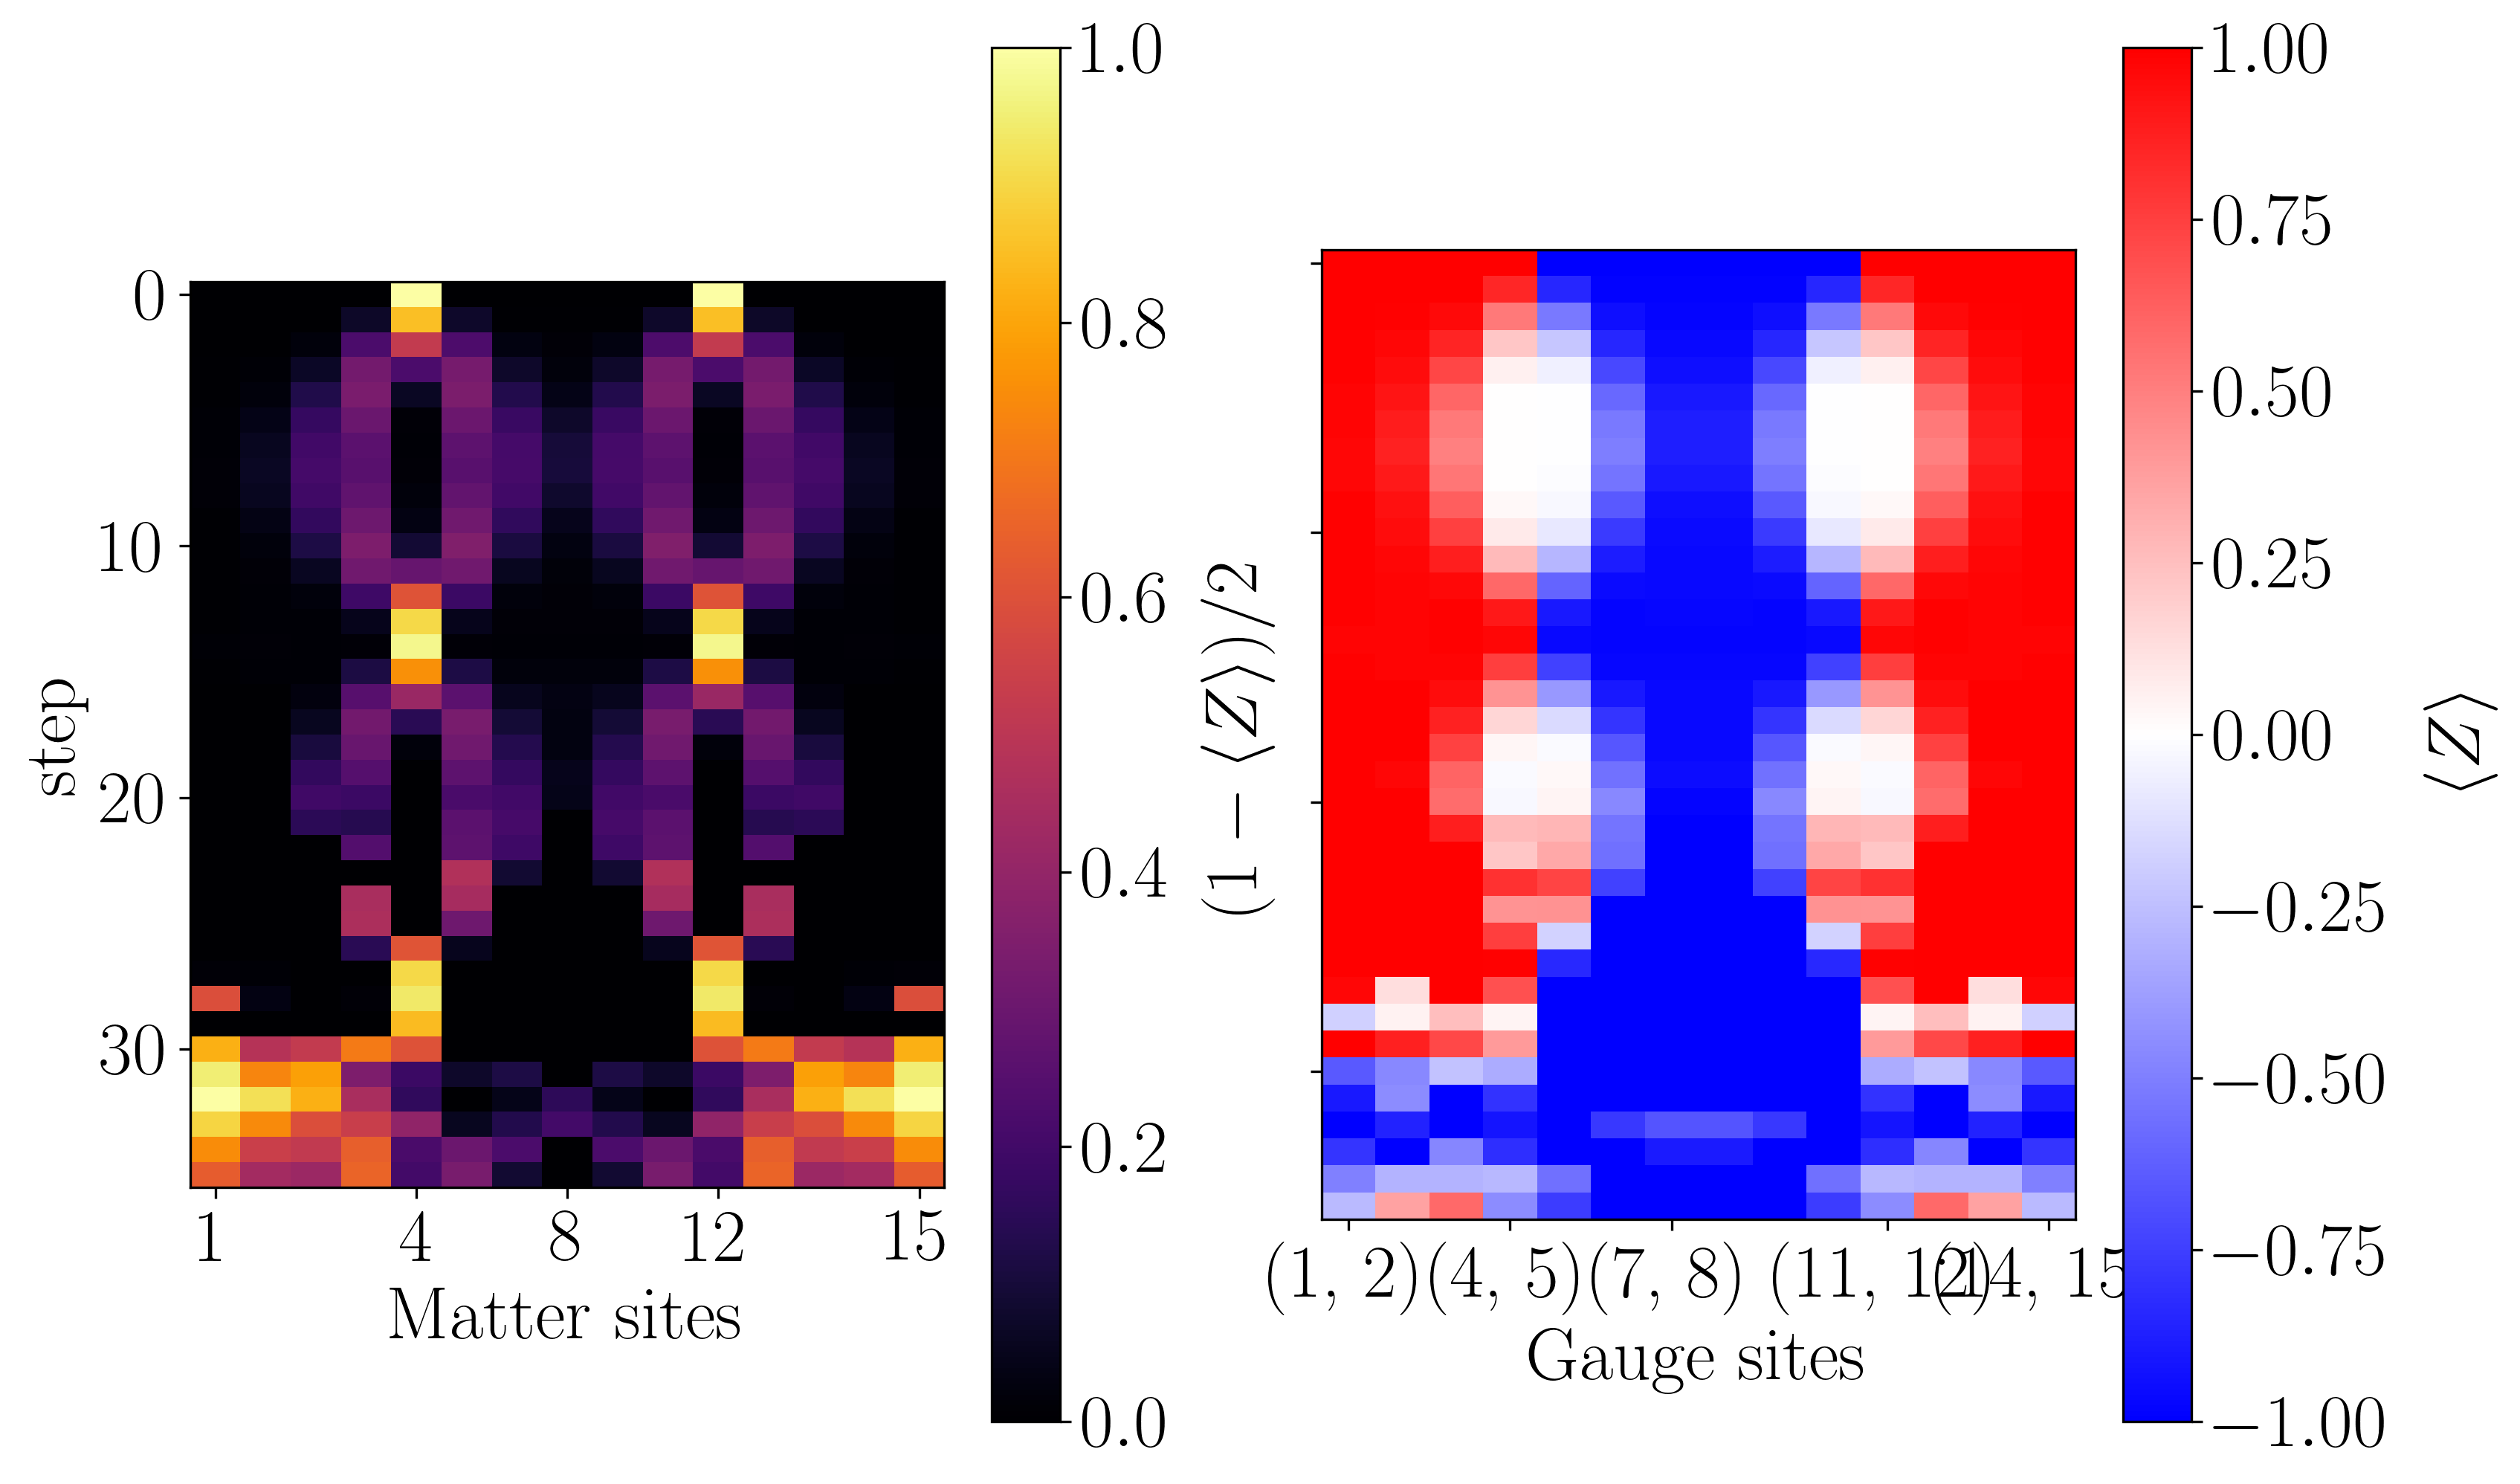

In [24]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp, cbar_range_matter=[0, 1], cbar_range_gauge=[-1, 1])

## Conventional

In [25]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_ct = 0.14705882*2
steps_ct = int(np.ceil(final_time/dt_ct))
# comparison_increment_ct = int(dt_ct/dt)
cutoff = 1e-12

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt_ct}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps_ct}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_ct = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt_ct, steps_ct, x_basis, False, cutoff)
    observable_matrix_ct = np.array(observable_matrix_ct)
    save_site_gauge_observable_matrix(observable_matrix_ct, filepath)
else:
    observable_matrix_ct = load_site_gauge_observable_matrix(filepath)

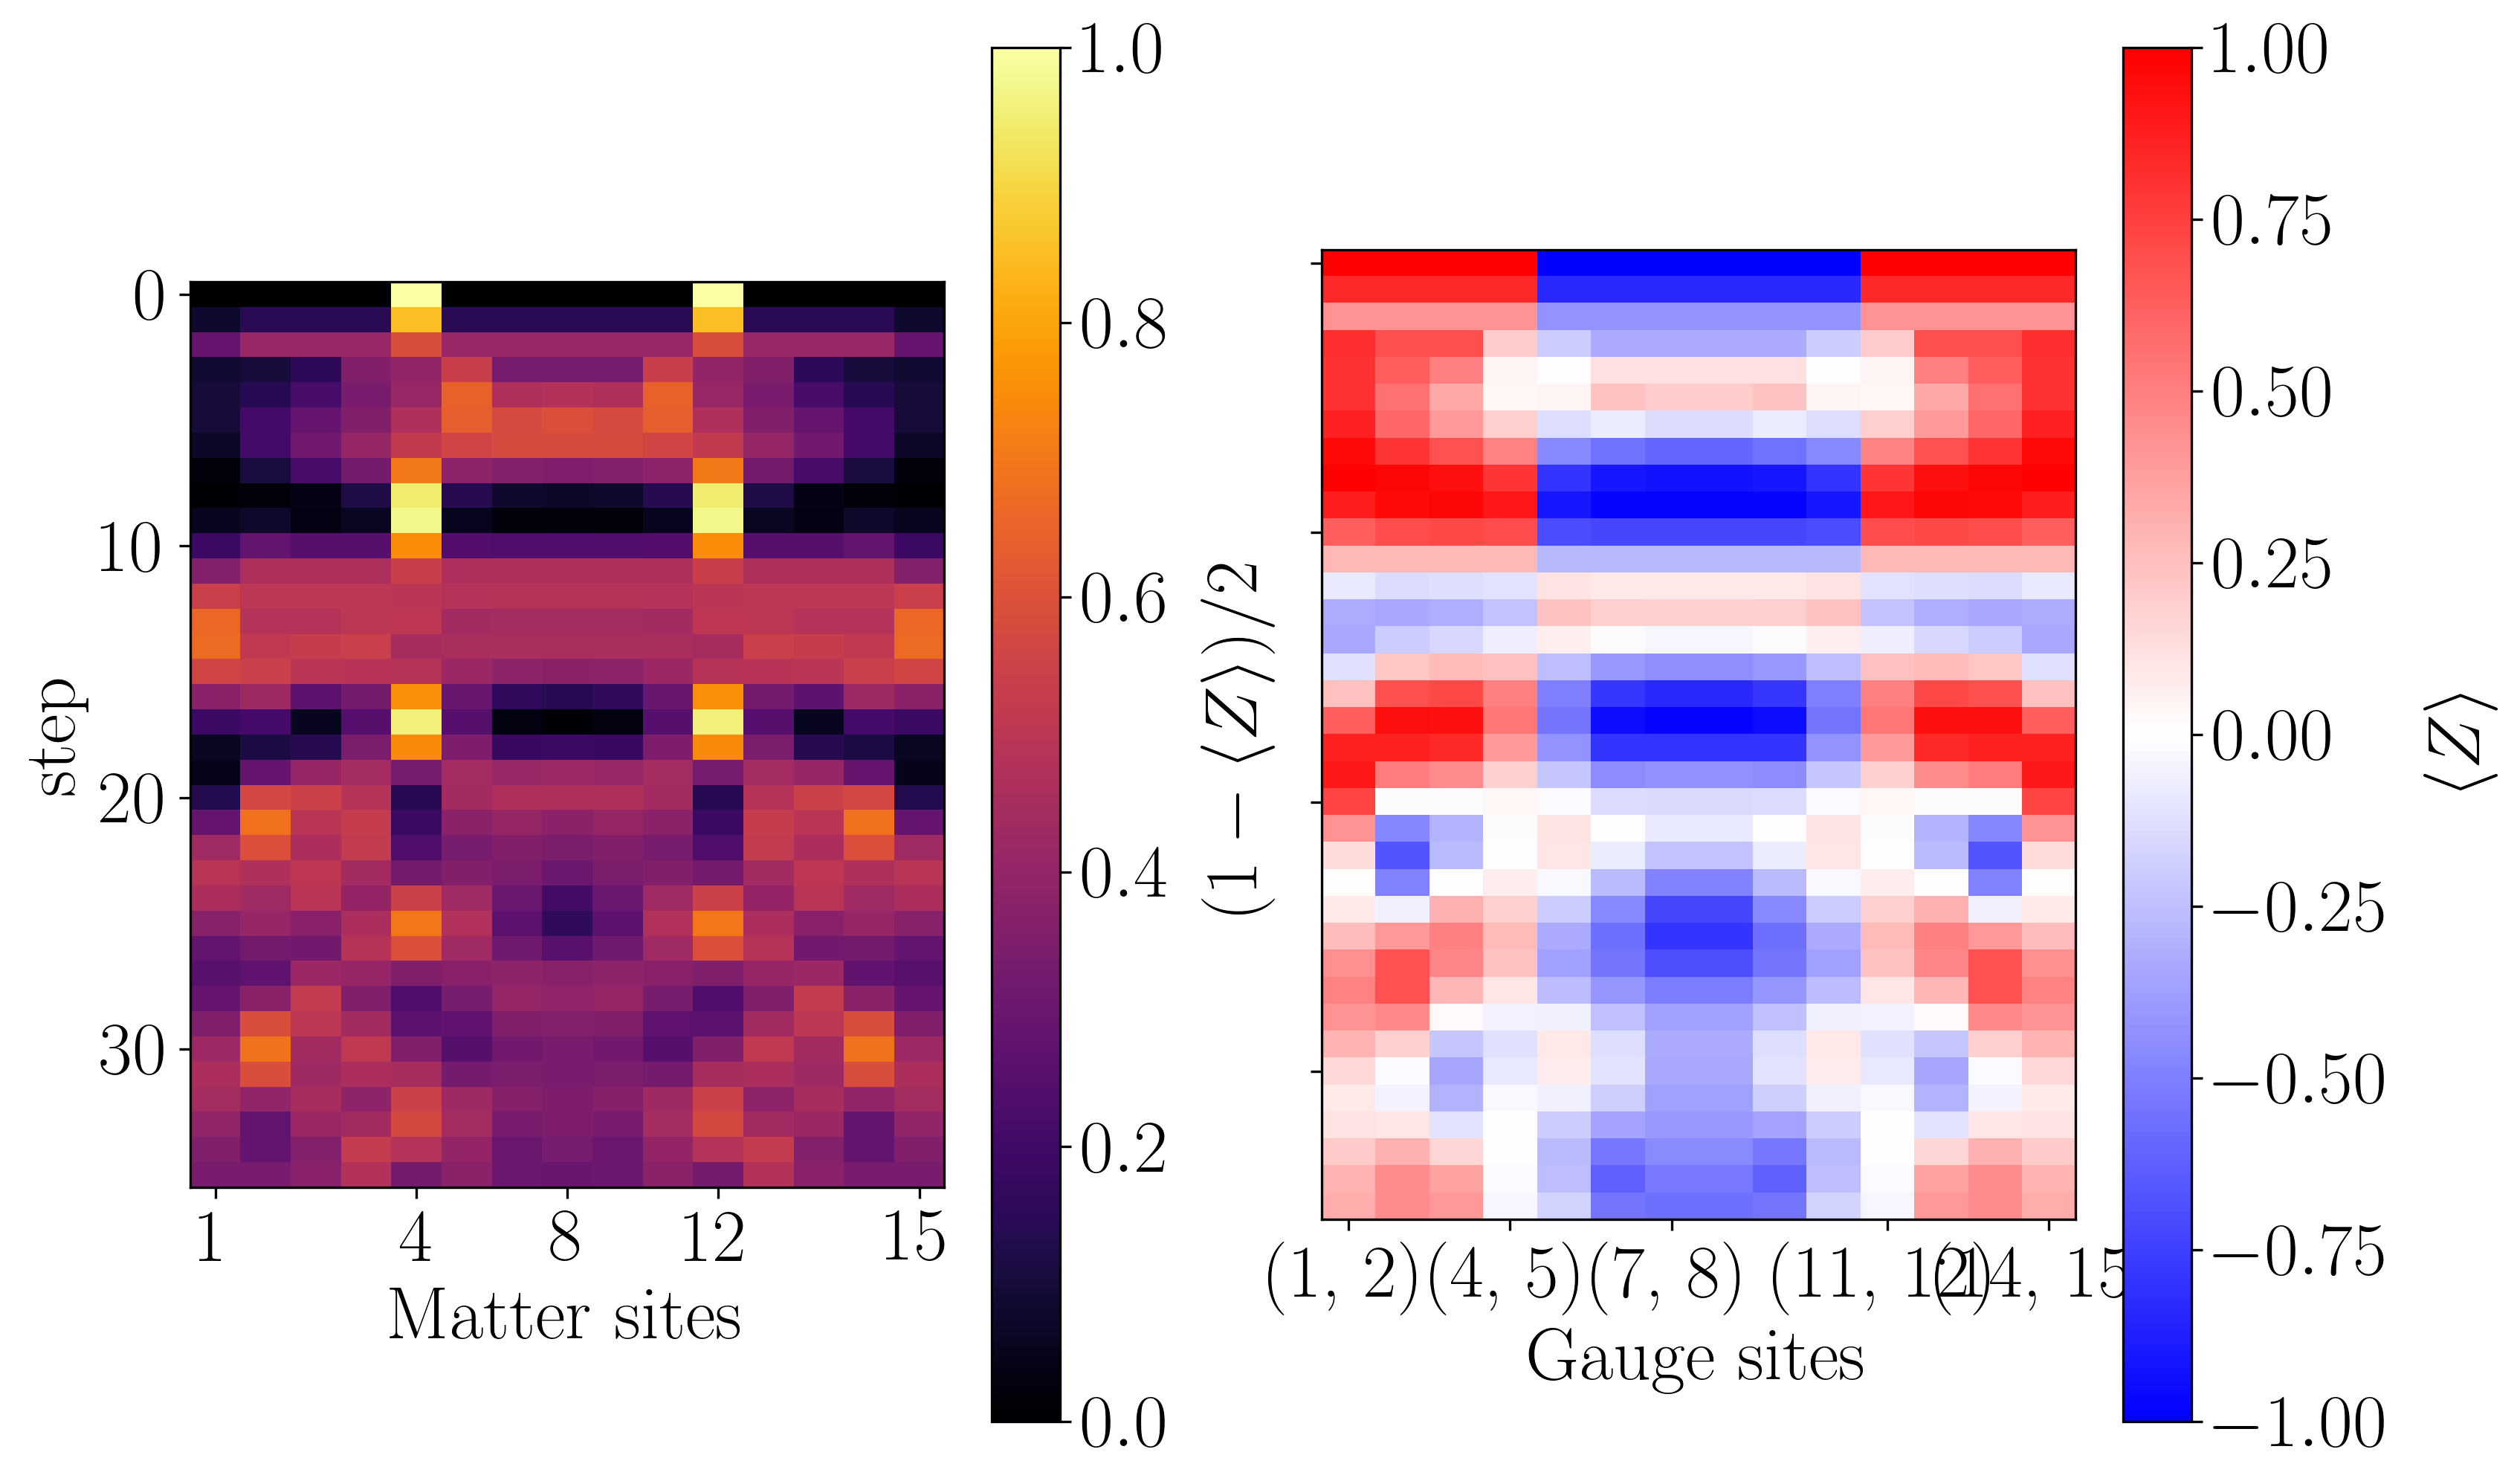

In [26]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_ct)

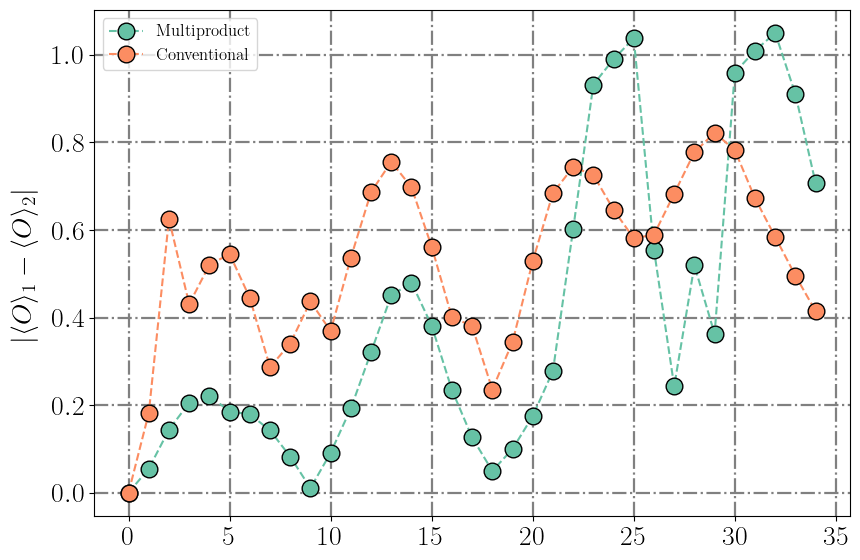

In [27]:
from utils.plotting import plot_mean_deviations

# x_ticks = [
#     np.arange(0, steps+1, (steps)//4),
#     np.linspace(0, final_time, 5)
# ]

comparison_increment = 20

plot_mean_deviations([observable_matrix_mp[:-1], observable_matrix_ct[:-1]], [observable_matrix[::comparison_increment]]*2, labels=["Multiproduct", "Conventional"])

# Well-conditioned multiproduct

## Playground

In [14]:
import utils.multiproductf as mpf

t = 8
nks = 3
k_max = 34

k_candidates, coefficients, condition_numbers, cost_func_values = mpf.search_mpf_parameters_ccost(t, nks, 2, k_max, mpf.k_a_onenorm_cost, return_costs=True)

## Multiproduct

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp = 0.14705882*2
steps_mp = int(np.ceil(final_time/dt_mp))
# comparison_increment_mp = int(dt_mp/dt)
multiproduct_lambda = 2
cutoff = 1e-12

filepath = f"Results/tnjulia_wcmultiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_maxk_{k_max}_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_particle_pair_simulation_2order(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, k_max, cutoff)
    observable_matrix_mp = np.array(observable_matrix_mp)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp = load_site_gauge_observable_matrix(filepath)

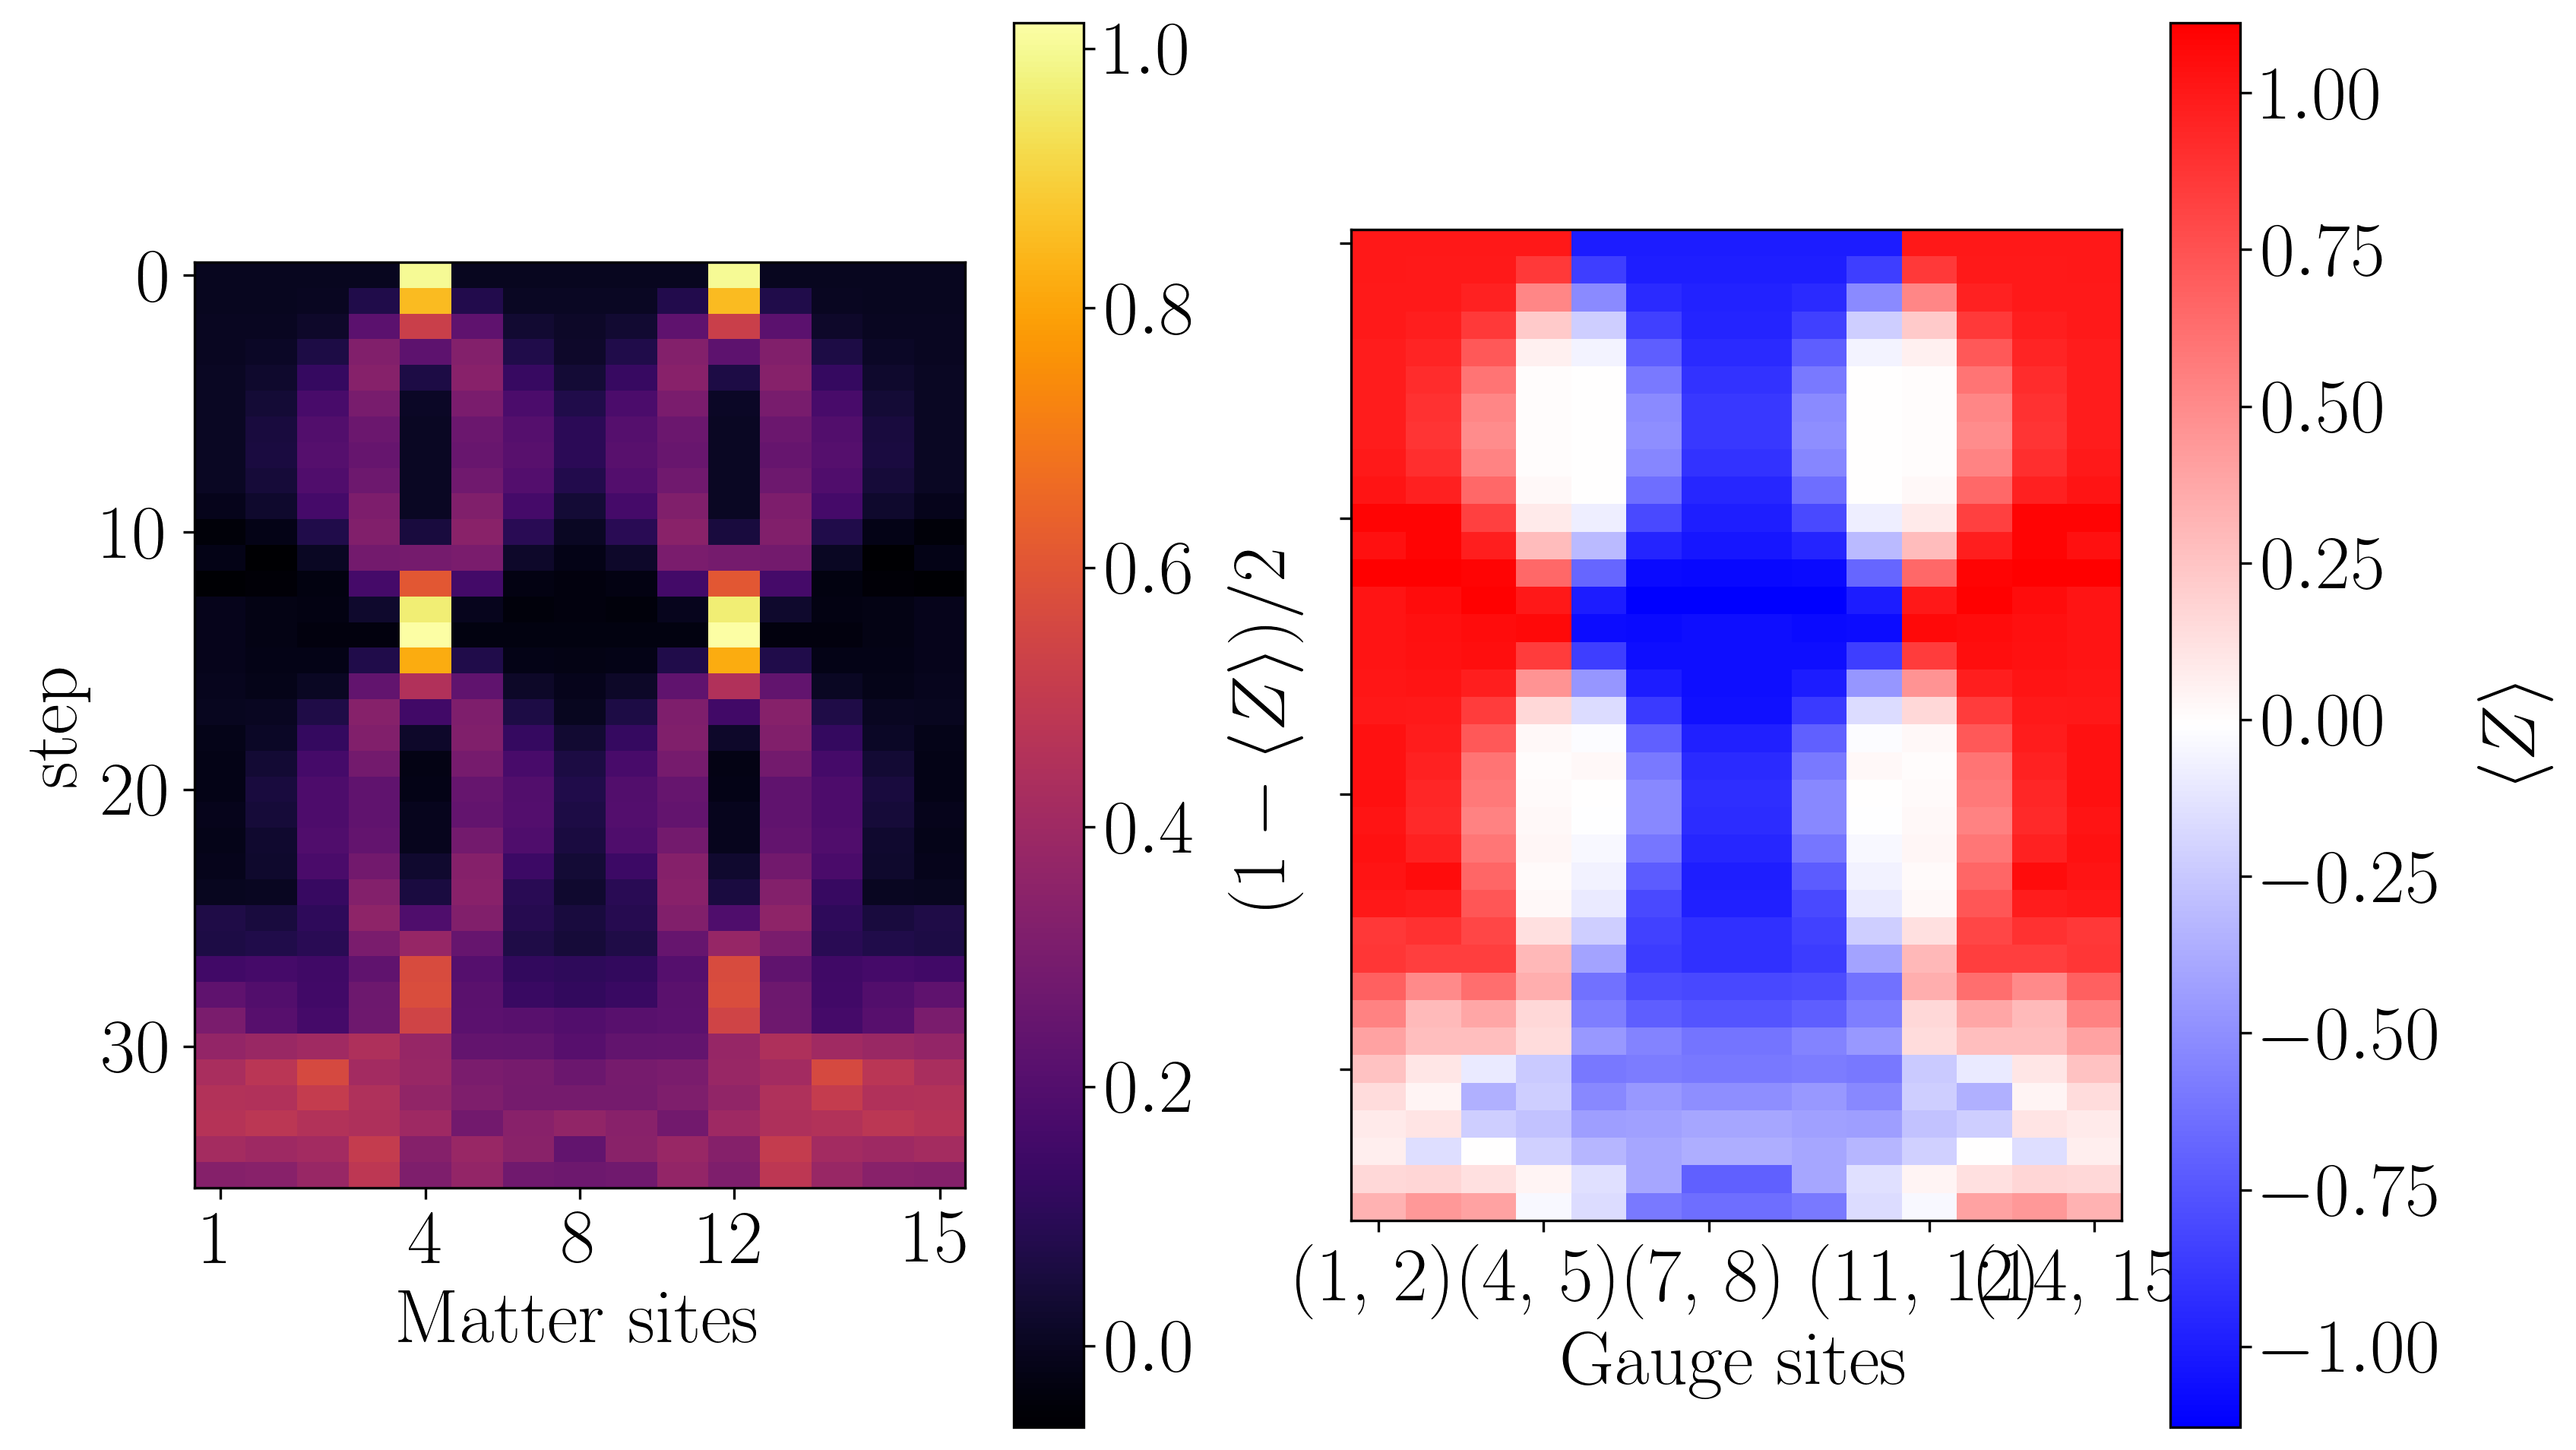

In [30]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp, filepath="MPF simulation.png")

## Circuit depth

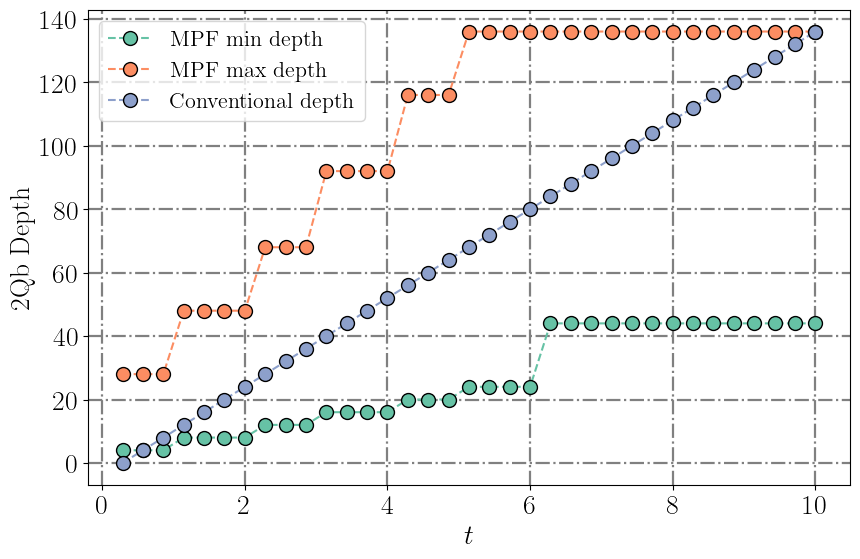

In [31]:
import matplotlib.pyplot as plt
import numpy as np

filepath = "MPF 1D depth.png"

times_arr = np.linspace(0, final_time, steps_mp+1)
ks = np.zeros((steps_mp, 3))
for i, t in enumerate(times_arr[1::]):
    this_ks, _, _ = jl.MultiProductF.search_mpf_parameters_ccost(t, 3, 2, k_max, jl.MultiProductF.k_a_disp_onenorm_cost)
    ks[i, :] = np.array(this_ks)[0]

min_depth_mpf = 4*np.min(ks, axis=1)
max_depth_mpf = 4*np.max(ks, axis=1)

conventional_depth = 4*(times_arr[1::] // dt_mp)

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
cmap = plt.get_cmap("Set2")

plt.plot(times_arr[1::], min_depth_mpf, "o--", markersize=10, markeredgecolor="black", color=cmap(0), label="MPF min depth")
plt.plot(times_arr[1::], max_depth_mpf, "o--", color=cmap(1), markersize=10, markeredgecolor="black", label="MPF max depth")
plt.plot(times_arr[1::], conventional_depth, "o--", color=cmap(2), markersize=10, markeredgecolor="black", label="Conventional depth")
plt.xlabel(r"$t$")
plt.ylabel("2Qb Depth")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.legend(loc="best", fontsize=16)
plt.tight_layout()
if filepath:
    plt.savefig(filepath, dpi=300, facecolor="none")
plt.show()
plt.rcdefaults()

# Conventional

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_ct = 0.14705882*2
steps_ct = int(np.ceil(final_time/dt_ct))
# comparison_increment_ct = int(dt_ct/dt)
cutoff = 1e-12

filepath = f"Results/tnjulia_z2pairquench_maxt_{final_time}_dt_{dt_ct}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_xbasis_{x_basis}_steps_{steps_ct}_cutoff_{cutoff}.npy"
overwrite = False

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_ct = jl.Z2HiggsChainDynamics.particle_pair_quench_simulation(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, dt_ct, steps_ct, x_basis, False, cutoff)
    observable_matrix_ct = np.array(observable_matrix_ct)
    save_site_gauge_observable_matrix(observable_matrix_ct, filepath)
else:
    observable_matrix_ct = load_site_gauge_observable_matrix(filepath)

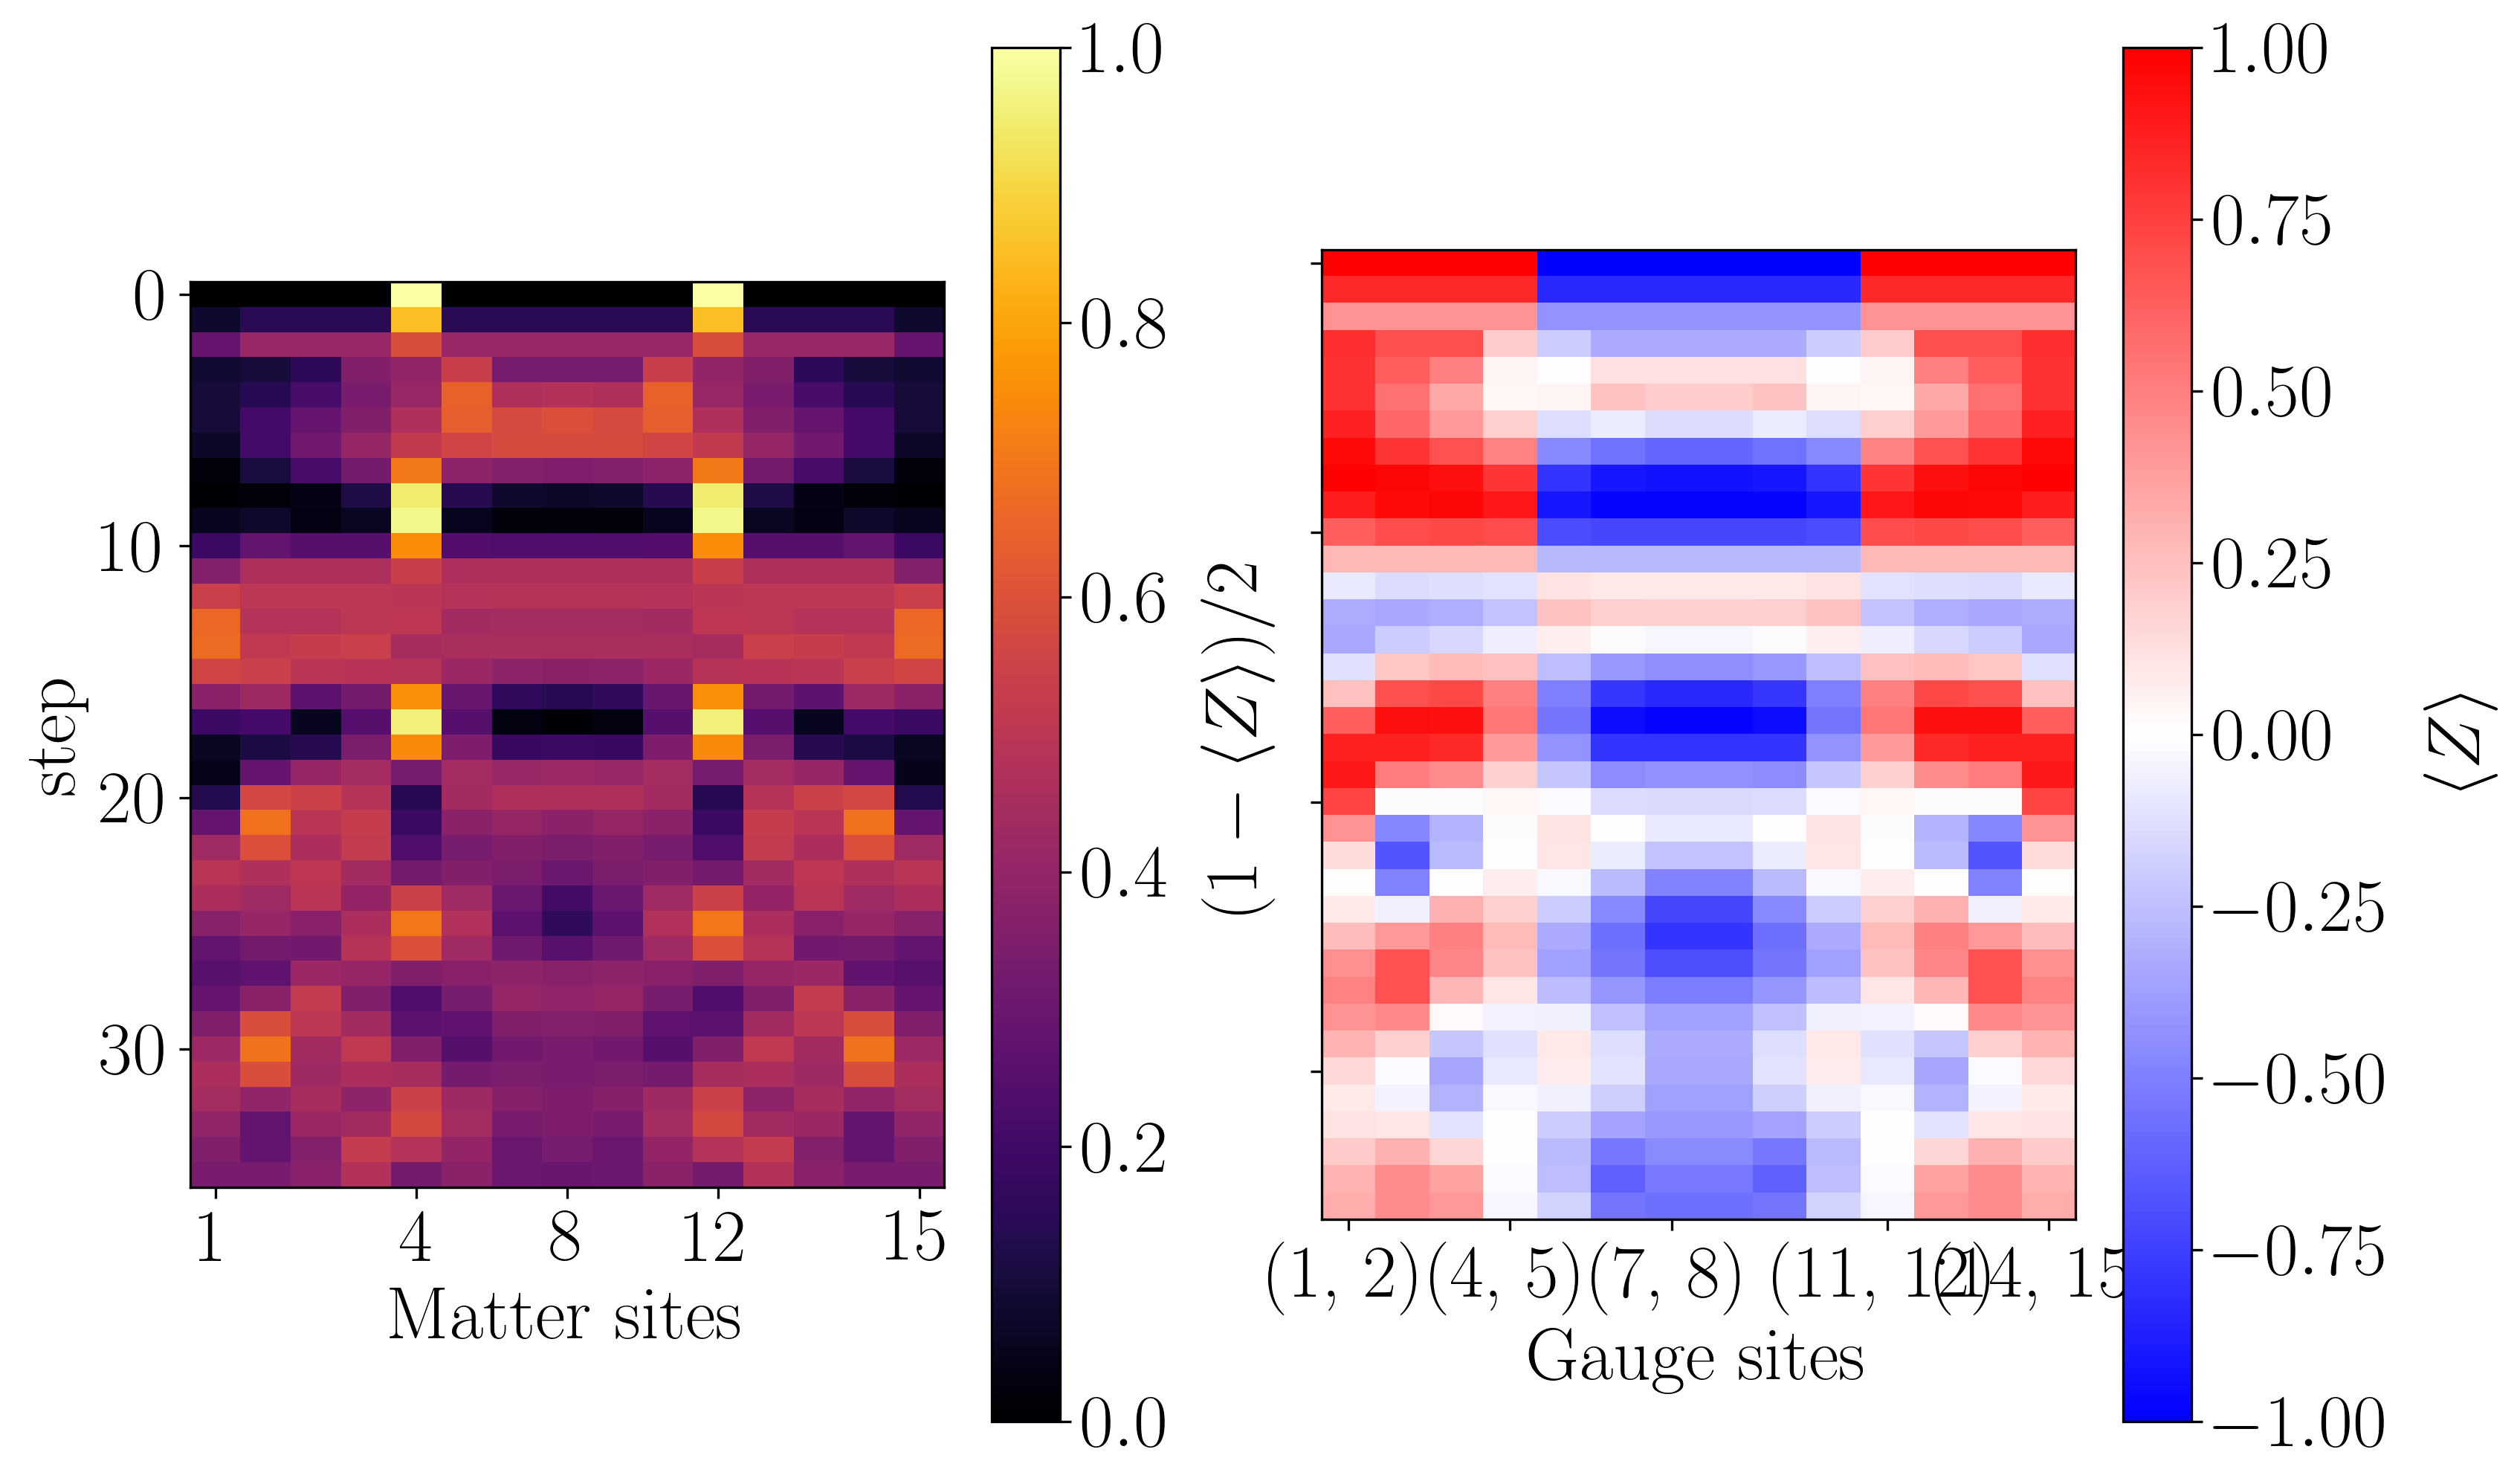

In [33]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_ct, filepath="Conventional simulation.png")

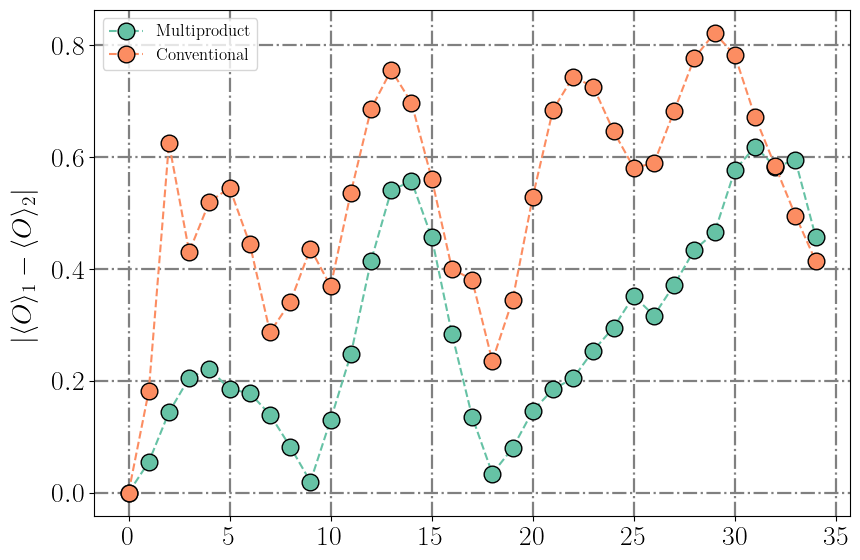

In [34]:
from utils.plotting import plot_mean_deviations

# x_ticks = [
#     np.arange(0, steps+1, (steps)//4),
#     np.linspace(0, final_time, 5)
# ]

comparison_increment = 20

plot_mean_deviations([observable_matrix_mp[:-1], observable_matrix_ct[:-1]], [observable_matrix[::comparison_increment]]*2, labels=["Multiproduct", "Conventional"])

# Fair comparison for long times

## Simulation

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp = 0.14705882*2
steps_mp = int(np.ceil(final_time/dt_mp))
# comparison_increment_mp = int(dt_mp/dt)
min_k_max = 20
cutoff = 1e-12

filepath = f"Results/tnjulia_wcmultiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_dtmaxk_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = False

jl.seval(f"max_k_func(t) = MultiProductF.dt_limited_max_k(t, {dt_mp}; min_k_max={min_k_max})")

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_particle_pair_simulation_2order(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, jl.max_k_func, cutoff)
    observable_matrix_mp = np.array(observable_matrix_mp)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp = load_site_gauge_observable_matrix(filepath)

Step 35

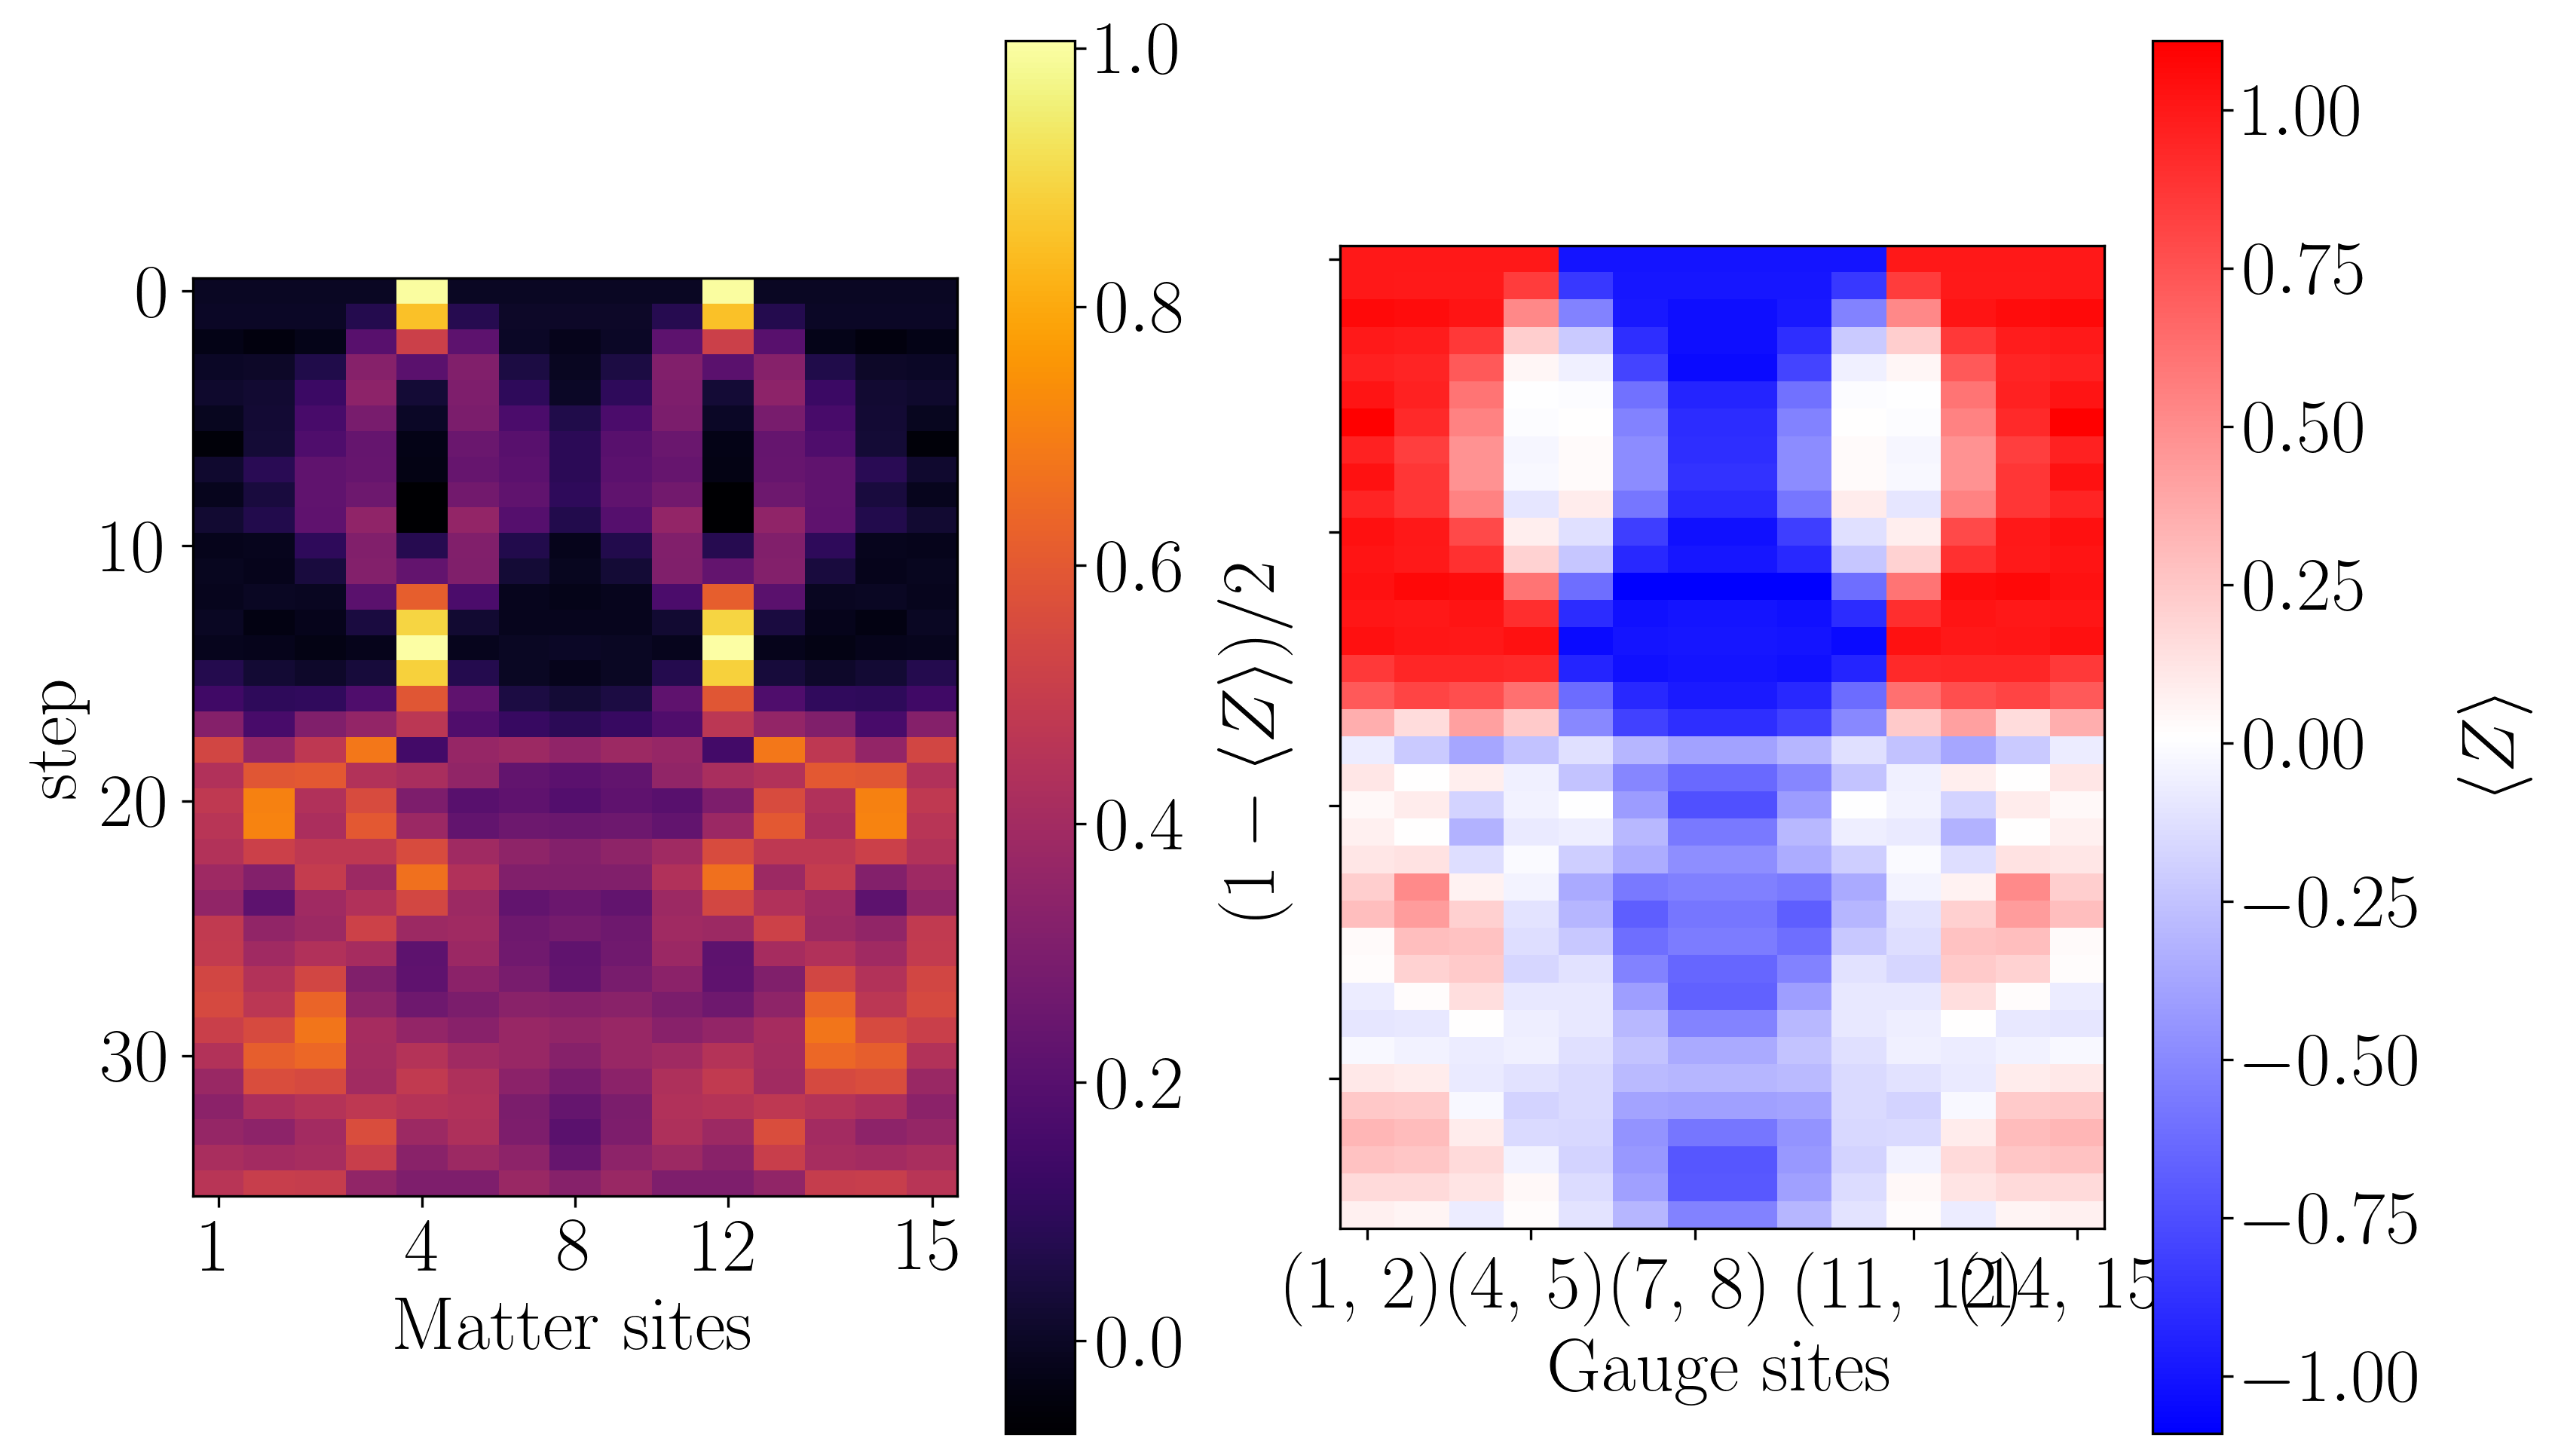

In [18]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp, filepath="MPF fair simulation.png")

## Depth & Coefficients

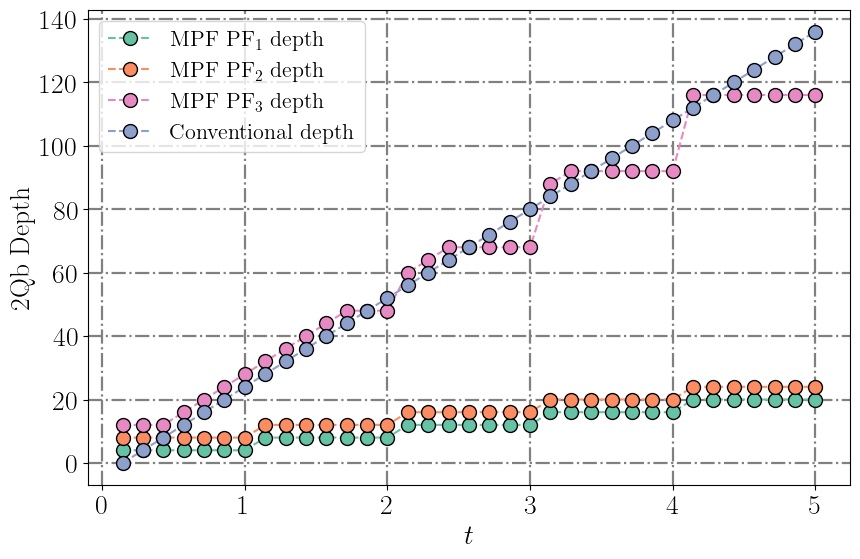

In [13]:
import matplotlib.pyplot as plt
import numpy as np

filepath = "MPF 1D depth.png"

times_arr = np.linspace(0, final_time, steps_mp+1)
ks = np.zeros((steps_mp, 3))
for i, t in enumerate(times_arr[1::]):
    this_ks, _, _ = jl.MultiProductF.search_mpf_parameters_ccost(t, 3, 2, jl.max_k_func, jl.MultiProductF.k_a_disp_onenorm_cost)
    ks[i, :] = np.array(this_ks)[0]

first_depth_mpf = 4*np.min(ks, axis=1)
max_depth_mpf = 4*np.max(ks, axis=1)

conventional_depth = 4*(times_arr[1::] // dt_mp)

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
cmap = plt.get_cmap("Set2")

plt.plot(times_arr[1::], 4*ks[:, 0], "o--", markersize=10, markeredgecolor="black", color=cmap(0), label=r"MPF $\mathrm{PF}_1$ depth")
plt.plot(times_arr[1::], 4*ks[:, 1], "o--", color=cmap(1), markersize=10, markeredgecolor="black", label=r"MPF $\mathrm{PF}_2$ depth")
plt.plot(times_arr[1::], 4*ks[:, 2], "o--", color=cmap(3), markersize=10, markeredgecolor="black", label=r"MPF $\mathrm{PF}_3$ depth")
plt.plot(times_arr[1::], conventional_depth, "o--", color=cmap(2), markersize=10, markeredgecolor="black", label="Conventional depth")

plt.xlabel(r"$t$")
plt.ylabel("2Qb Depth")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.legend(loc="best", fontsize=16)
plt.tight_layout()
if filepath:
    plt.savefig(filepath, dpi=300, facecolor="none")
plt.show()
plt.rcdefaults()

## Always fair comparison

In [ ]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp = 0.14705882*2
steps_mp = int(np.ceil(final_time/dt_mp))
# comparison_increment_mp = int(dt_mp/dt)
min_k_max = 3
cutoff = 1e-12

filepath = f"Results/tnjulia_wcmultiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_dtmaxk_minkmax_{min_k_max}_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = False

jl.seval(f"max_k_func(t) = MultiProductF.dt_limited_max_k(t, {dt_mp}; min_k_max={min_k_max})")

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_particle_pair_simulation_2order(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, jl.max_k_func, cutoff)
    observable_matrix_mp = np.array(observable_matrix_mp)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp = load_site_gauge_observable_matrix(filepath)

Step 35

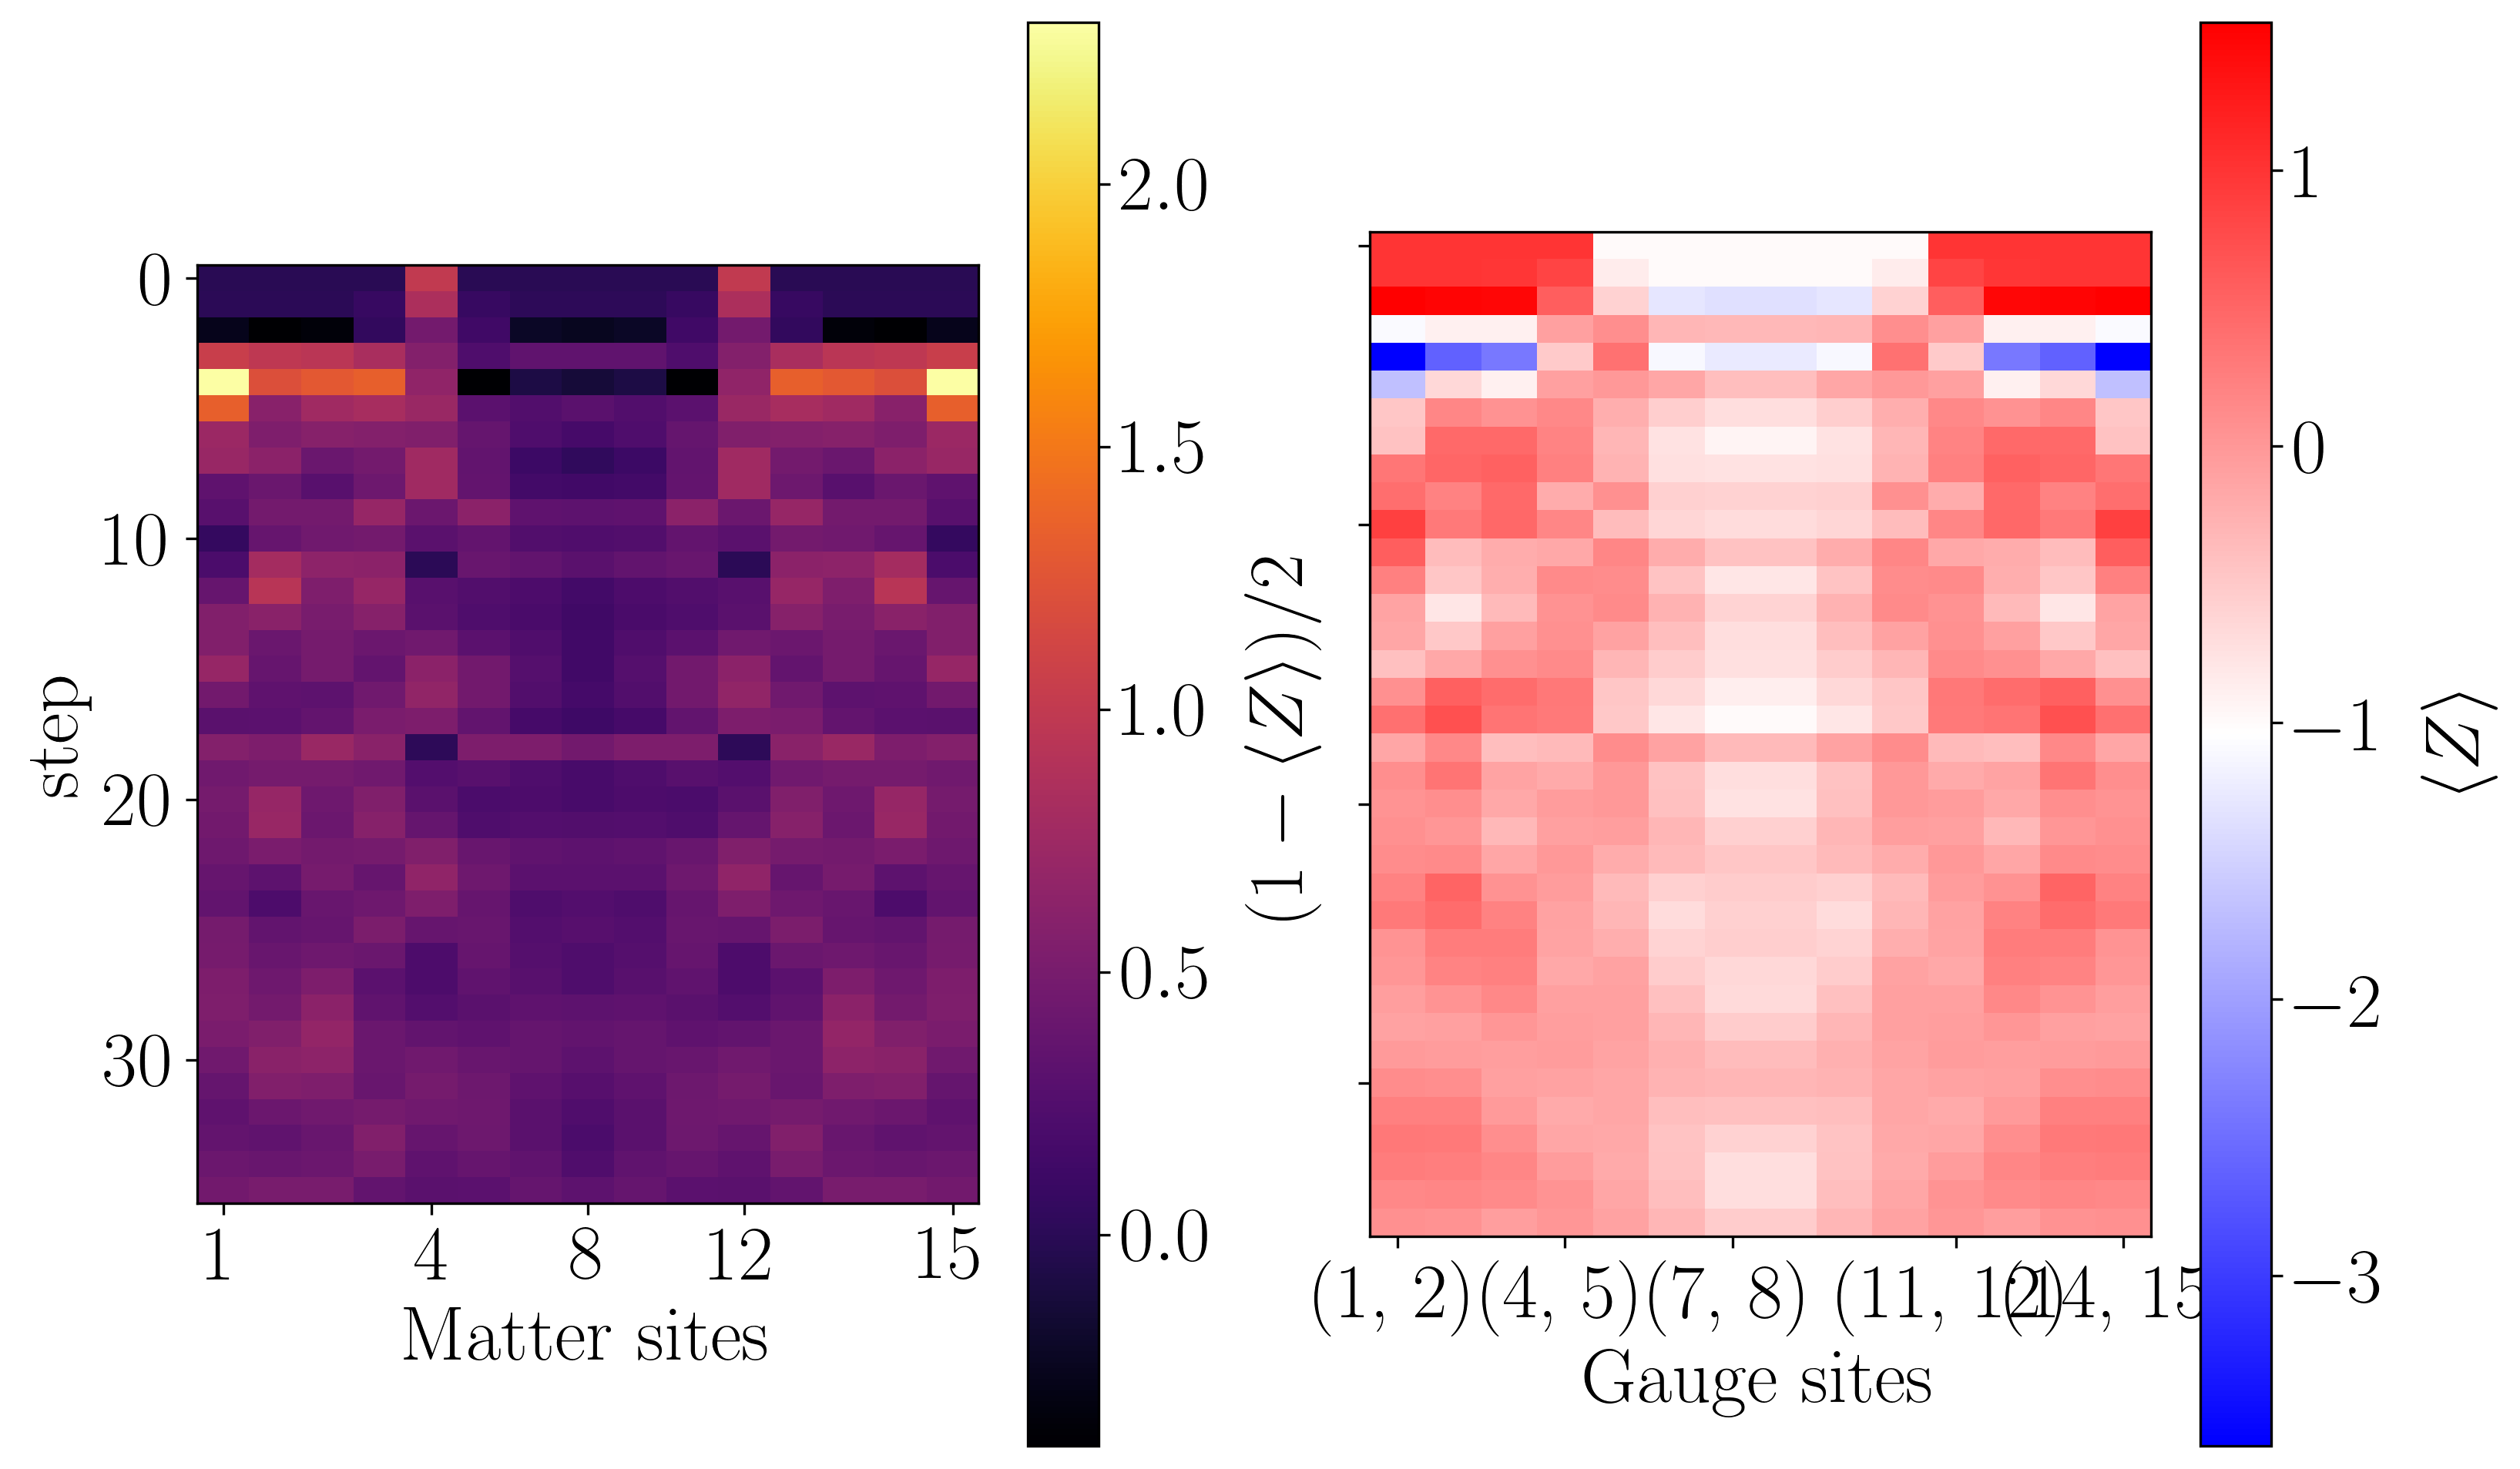

In [21]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp, filepath="MPF fair simulation.png")

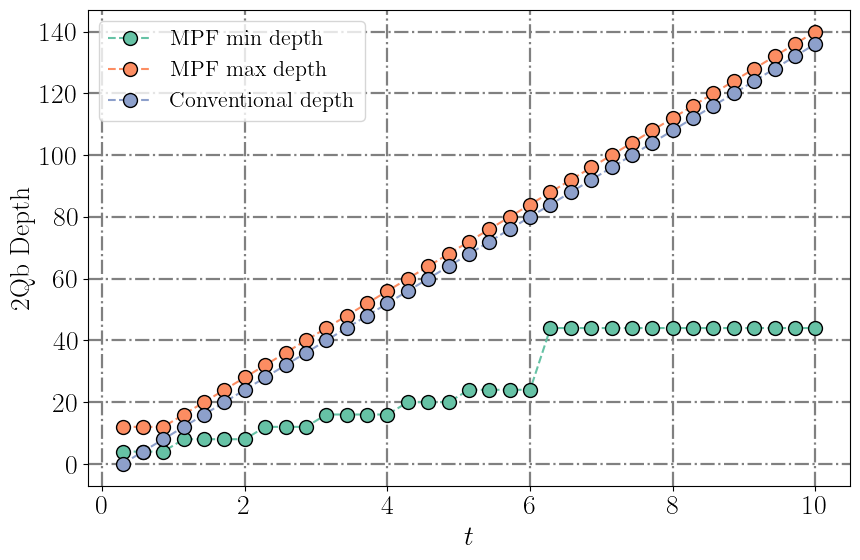

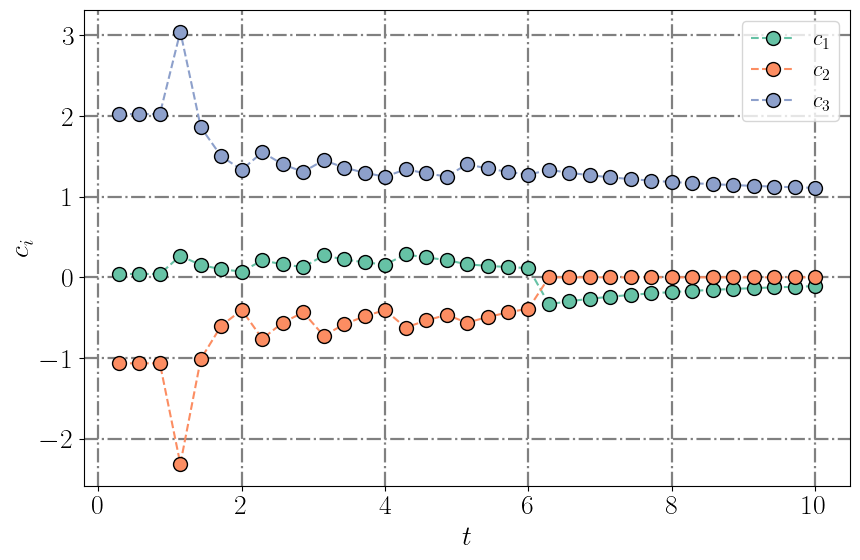

In [22]:
import matplotlib.pyplot as plt
import numpy as np

filepath_depth = "MPF 1D depth.png"
filepath_coeff = "MPF 1D coeffs.png"

times_arr = np.linspace(0, final_time, steps_mp+1)
ks = np.zeros((steps_mp, 3))
coefficients = np.zeros((steps_mp, 3))
for i, t in enumerate(times_arr[1::]):
    this_ks, this_coefficients, _ = jl.MultiProductF.search_mpf_parameters_ccost(t, 3, 2, jl.max_k_func, jl.MultiProductF.k_a_disp_onenorm_cost)
    ks[i, :] = np.array(this_ks)[0]
    coefficients[i, :] = np.array(this_coefficients)[0]

min_depth_mpf = 4*np.min(ks, axis=1)
max_depth_mpf = 4*np.max(ks, axis=1)

conventional_depth = 4*(times_arr[1::] // dt_mp)

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
cmap = plt.get_cmap("Set2")

plt.plot(times_arr[1::], min_depth_mpf, "o--", markersize=10, markeredgecolor="black", color=cmap(0), label="MPF min depth")
plt.plot(times_arr[1::], max_depth_mpf, "o--", color=cmap(1), markersize=10, markeredgecolor="black", label="MPF max depth")
plt.plot(times_arr[1::], conventional_depth, "o--", color=cmap(2), markersize=10, markeredgecolor="black", label="Conventional depth")
plt.xlabel(r"$t$")
plt.ylabel("2Qb Depth")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.legend(loc="best", fontsize=16)
plt.tight_layout()
if filepath_depth:
    plt.savefig(filepath_depth, dpi=300, facecolor="none")
plt.show()

fig, ax = plt.subplots(figsize=[9, 6])
cmap = plt.get_cmap("Set2")

plt.plot(times_arr[1::], coefficients[:, 0], "o--", markersize=10, markeredgecolor="black", color=cmap(0), label=r"$c_1$")
plt.plot(times_arr[1::], coefficients[:, 1], "o--", markersize=10, markeredgecolor="black", color=cmap(1), label=r"$c_2$")
plt.plot(times_arr[1::], coefficients[:, 2], "o--", markersize=10, markeredgecolor="black", color=cmap(2), label=r"$c_3$")
plt.xlabel(r"$t$")
plt.ylabel(r"$c_i$")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.legend(loc="best", fontsize=16)
plt.tight_layout()
if filepath_coeff:
    plt.savefig(filepath_coeff, dpi=300, facecolor="none")
plt.show()

## With fixed optimization

In [5]:
from utils.plotting import load_site_gauge_observable_matrix, save_site_gauge_observable_matrix
import numpy as np
import os

dt_mp = 0.14705882*2
steps_mp = int(np.ceil(final_time/dt_mp))
# comparison_increment_mp = int(dt_mp/dt)
min_k_max = 20
cutoff = 1e-12

filepath = f"Results/tnjulia_wcmultiproduct_z2pairquench_maxt_{final_time}_dt_{dt_mp}_L_{L}_J_{m:.04f}_h_{g:.04f}_lamb_{lamb:.04f}_pp_{particle_pair_left_position}_pl_{particle_pair_length}_dtmaxk_xbasis_{x_basis}_steps_{steps_mp}_cutoff_{cutoff}.npy"
overwrite = True

jl.seval(f"max_k_func(t) = MultiProductF.dt_limited_max_k(t, {dt_mp}; min_k_max={min_k_max})")

if overwrite or not os.path.exists(filepath):
    sites = jl.Z2HiggsChainDynamics.chain_sites(L)
    observables = jl.Z2HiggsChainDynamics.all_local_pauli_z(sites)
    ks, coefficients, _ = jl.MultiProductF.search_mpf_parameters_ccost(1, 3, 2, 35, jl.MultiProductF.k_a_onenorm_cost)
    base_ks = jl.copy(ks[0])
    base_coefficients = jl.copy(coefficients[0, :])
    observable_matrix_mp = jl.Z2HiggsChainDynamics.multiproduct_particle_pair_simulation_2order(sites, observables, m, g, lamb, particle_pair_left_position, particle_pair_length, final_time, steps_mp, dt_mp, base_ks, base_coefficients, cutoff)
    observable_matrix_mp = np.array(observable_matrix_mp)
    save_site_gauge_observable_matrix(observable_matrix_mp, filepath)
else:
    observable_matrix_mp = load_site_gauge_observable_matrix(filepath)

Step 35

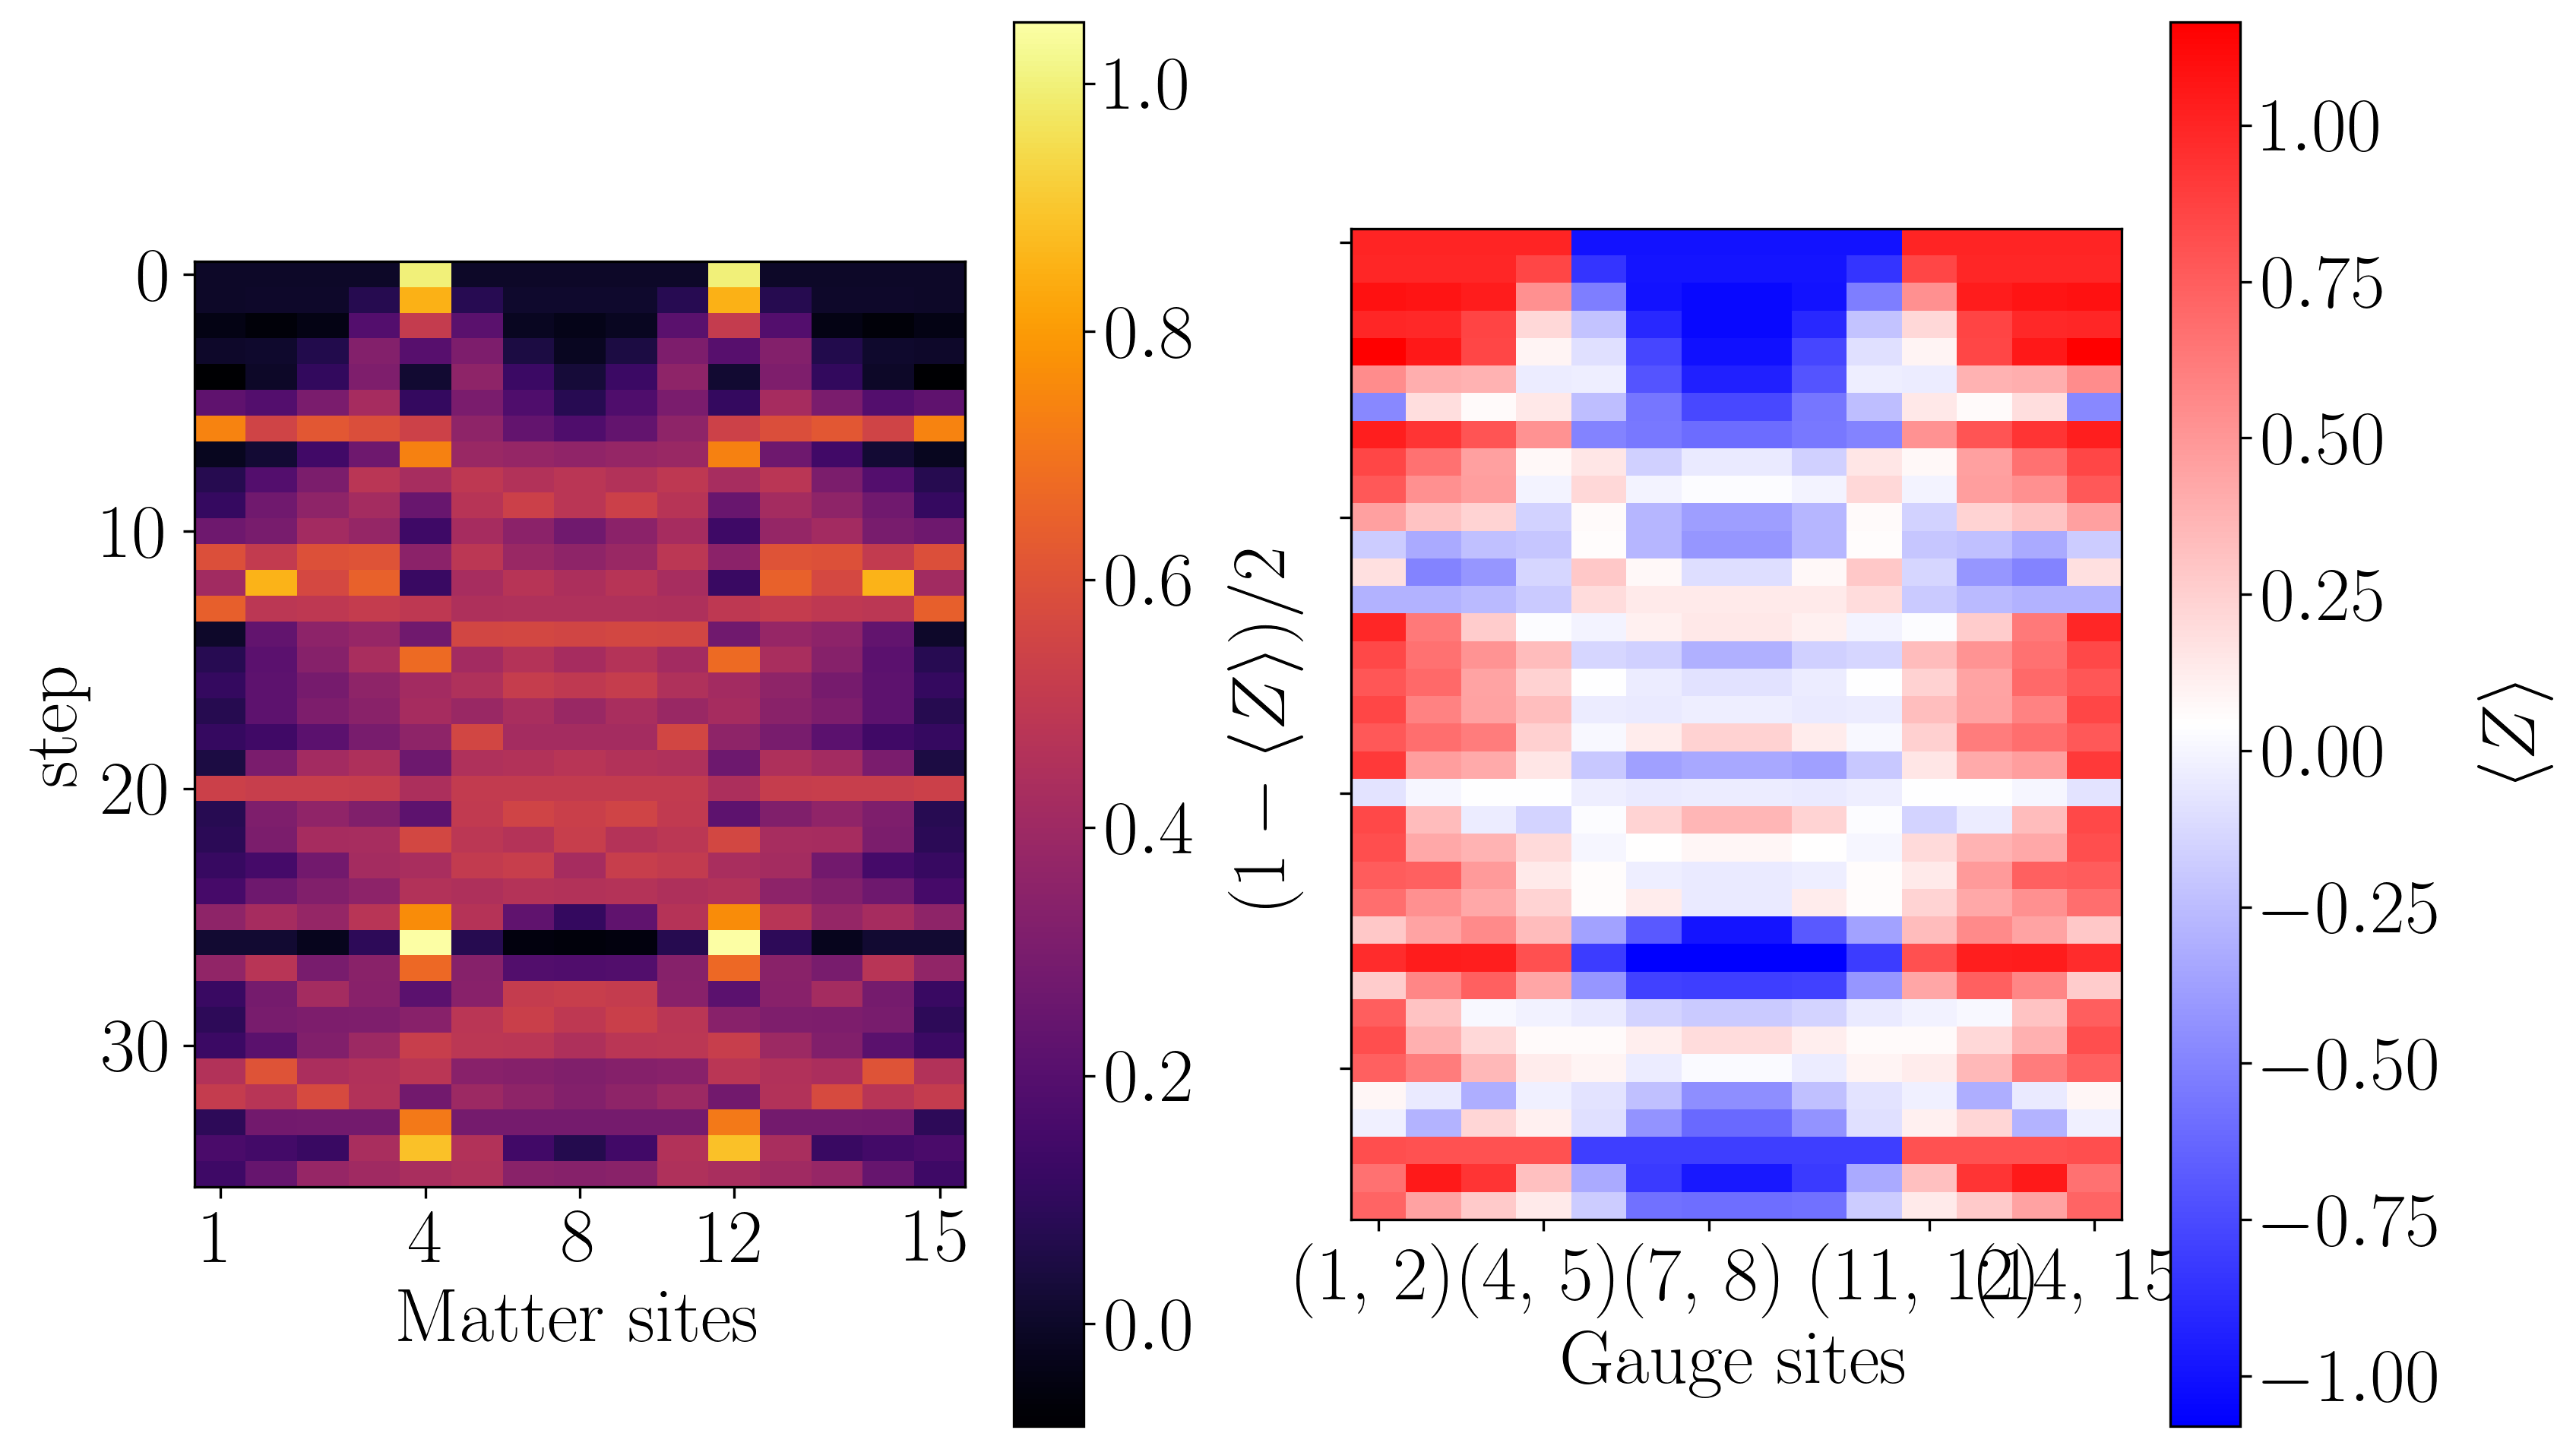

In [6]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(observable_matrix_mp)

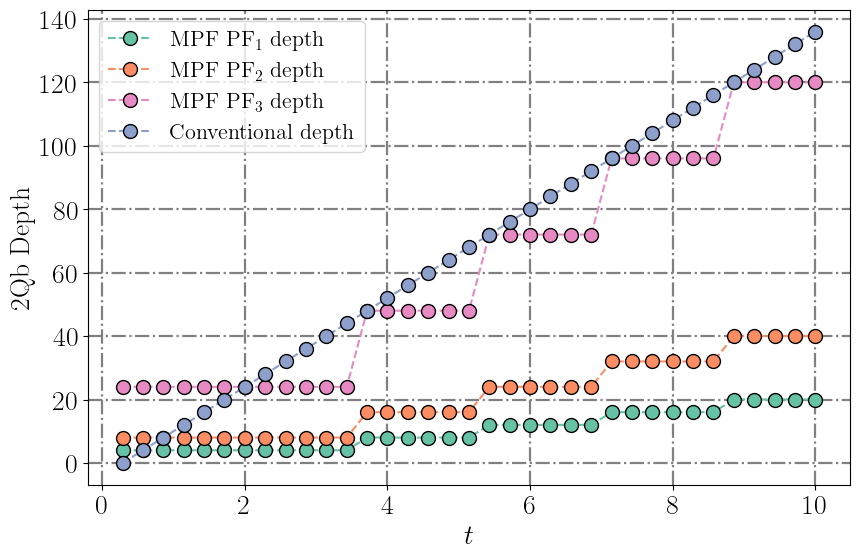

In [7]:
import matplotlib.pyplot as plt
import numpy as np

filepath = "MPF 1D depth.png"

times_arr = np.linspace(0, final_time, steps_mp+1)
ks = np.zeros((steps_mp, 3))
for i, t in enumerate(times_arr[1::]):
    # ks[i, :] = int(np.ceil(t)) * np.array(base_ks)
    ks[i, :] = np.array(base_ks) * ((t / dt_mp) // base_ks[-1] if ((t / dt_mp) // base_ks[-1]) > 0 else 1)

first_depth_mpf = 4*np.min(ks, axis=1)
max_depth_mpf = 4*np.max(ks, axis=1)

conventional_depth = 4*(times_arr[1::] // dt_mp)

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
cmap = plt.get_cmap("Set2")

plt.plot(times_arr[1::], 4*ks[:, 0], "o--", markersize=10, markeredgecolor="black", color=cmap(0), label=r"MPF $\mathrm{PF}_1$ depth")
plt.plot(times_arr[1::], 4*ks[:, 1], "o--", color=cmap(1), markersize=10, markeredgecolor="black", label=r"MPF $\mathrm{PF}_2$ depth")
plt.plot(times_arr[1::], 4*ks[:, 2], "o--", color=cmap(3), markersize=10, markeredgecolor="black", label=r"MPF $\mathrm{PF}_3$ depth")
plt.plot(times_arr[1::], conventional_depth, "o--", color=cmap(2), markersize=10, markeredgecolor="black", label="Conventional depth")

plt.xlabel(r"$t$")
plt.ylabel("2Qb Depth")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.legend(loc="best", fontsize=16)
plt.tight_layout()
if filepath:
    plt.savefig(filepath, dpi=300, facecolor="none")
plt.show()
plt.rcdefaults()